# Figure 6: age-conditioned normative-model analysis

This notebook documents the frozen 186-participant Figure 6 analysis. It distinguishes held-out
OOF calibration from full-cohort normative-curve estimation. No candidate model is added, no
participant is excluded from statistical results, and no Gaussian fallback is permitted.

## 1. Data sources and frozen specification

In [30]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
import nibabel.freesurfer.io as fsio
from nilearn import plotting
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "figure6":
    candidate = ROOT / "analysis_results" / "figure6"
    if candidate.is_dir():
        ROOT = candidate
    else:
        raise RuntimeError("Run from the repository root, result root, or notebook directory.")

RESULT = ROOT / "ico4_warped_m2_186"
OOF = RESULT / "oof"
FULL = RESULT / "full_models"
FIG6C = RESULT / "figure6c"
FIG6C_SUPP = RESULT / "figure6c_supplement_age41_78"
SUMMARY = ROOT / "summary"
NOTEBOOK_FIGURE_DIR = ROOT / "notebook_figures" / "ico4_final_model_results_186"
NOTEBOOK_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required = [
    OOF / "combined_oof_validation.json",
    OOF / "calibration_overall.csv",
    OOF / "subject_bootstrap_calibration_ci.csv",
    OOF / "calibration_by_depth.csv",
    OOF / "calibration_by_hemisphere.csv",
    OOF / "calibration_by_age_group.csv",
    OOF / "calibration_by_node_depth.parquet",
    OOF / "left_parahippocampal_calibration.csv",
    OOF / "invalid_availability_positions.parquet",
    OOF / "all_oof_z.npy",
    FULL / "full_cohort_validation.json",
    FULL / "parameter_file_index.parquet",
    FULL / "centile_file_index.parquet",
    FULL / "representative_node_selection.csv",
    FULL / "representative_node_centiles.parquet",
    FULL / "age_curve_shape_diagnostics.parquet",
    ROOT / "regional_warped_m2_186" / "oof_predictions_gaussian_M0_M3_long.parquet",
    ROOT / "regional_warped_m2_186" / "oof_predictions_warped_M2_long.parquet",
    ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_node_information.csv",
    ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_node_21depth_predictions.parquet",
    ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_node_locations.png",
    ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_nodes_sex_code_2.png",
    ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_nodes_sex_code_1_supplement.png",
    FIG6C / "node_depth_standardized_age_effect.parquet",
    FIG6C / "node_depth_band_standardized_age_effect.parquet",
    FIG6C / "node_covariate_support.parquet",
    FIG6C / "age_support.csv",
    FIG6C / "computation_qc.json",
    FIG6C / "rendering_qc.json",
    FIG6C / "surface_mapping_qc.csv",
    FIG6C / "Figure6C_depth_stratified_age_association.png",
    FIG6C / "Figure6C_depth_stratified_age_association.pdf",
    FIG6C_SUPP / "node_depth_standardized_age_effect.parquet",
    FIG6C_SUPP / "node_depth_band_standardized_age_effect.parquet",
    FIG6C_SUPP / "age_support.csv",
    FIG6C_SUPP / "computation_qc.json",
    FIG6C_SUPP / "rendering_qc.json",
    FIG6C_SUPP / "Figure6C_supplement_age41_78.png",
    FIG6C_SUPP / "Figure6C_supplement_age41_78.pdf",
    SUMMARY / "figure6_overall_summary.png",
    SUMMARY / "figure6_numerical_summary.csv",
    SUMMARY / "figure6_numerical_summary.md",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Analysis is incomplete; missing:\n" + "\n".join(missing))

oof_validation = json.loads((OOF / "combined_oof_validation.json").read_text())
full_validation = json.loads((FULL / "full_cohort_validation.json").read_text())
overall = pd.read_csv(OOF / "calibration_overall.csv")
bootstrap = pd.read_csv(OOF / "subject_bootstrap_calibration_ci.csv")
by_depth = pd.read_csv(OOF / "calibration_by_depth.csv")
by_hemi = pd.read_csv(OOF / "calibration_by_hemisphere.csv")
by_age = pd.read_csv(OOF / "calibration_by_age_group.csv")
selection = pd.read_csv(FULL / "representative_node_selection.csv")
centiles = pd.read_parquet(FULL / "representative_node_centiles.parquet")

# Publication palette and drawing/export settings are kept in this notebook so every restored
# figure can be edited and regenerated here. Set WRITE_FIGURES=True when revised files should
# replace the existing PNG/PDF/SVG exports.
WRITE_FIGURES = False
COLORS = {
    "blue": "#4B74B2", "light_blue": "#90BEE0", "pale_blue": "#E6F1F3",
    "orange": "#FC8C5A", "red": "#DB3124", "yellow": "#FFDF92",
    "gray": "#8A8A8A", "dark_gray": "#333333",
}
POINT_SIZE = 9
POINT_EDGE_WIDTH = 2.0
LINE_WIDTH = 1.8

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "axes.grid": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "pdf.fonttype": 42,
    "ps.fonttype": 42, "svg.fonttype": "none",
})

def clean_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    ax.grid(False)

def export_figure(fig, stem):
    paths = []
    if WRITE_FIGURES:
        for suffix, kwargs in (("png", {"dpi": 600}), ("pdf", {}), ("svg", {})):
            path = NOTEBOOK_FIGURE_DIR / f"{stem}.{suffix}"
            fig.savefig(path, bbox_inches="tight", **kwargs)
            paths.append(path)
    return paths

exported_figures = []

frozen_specification = {
    "participants": 186,
    "excluded": {"D0271": "source_image_structural_abnormality",
                 "D0285": "source_image_structural_abnormality"},
    "fold_test_sizes": [38, 38, 37, 36, 37],
    "nodes": 4687,
    "depths": 21,
    "model": "Warped M2: linear age + categorical sex_code + local FreeSurfer thickness",
    "software": "PCNToolkit 1.3.0",
    "warp": "WarpSinhArcsinh",
    "variance": "homoskedastic",
}
frozen_specification

{'participants': 186,
 'excluded': {'D0271': 'source_image_structural_abnormality',
  'D0285': 'source_image_structural_abnormality'},
 'fold_test_sizes': [38, 38, 37, 36, 37],
 'nodes': 4687,
 'depths': 21,
 'model': 'Warped M2: linear age + categorical sex_code + local FreeSurfer thickness',
 'software': 'PCNToolkit 1.3.0',
 'warp': 'WarpSinhArcsinh',
 'variance': 'homoskedastic'}

## 2. Cohort age distributions

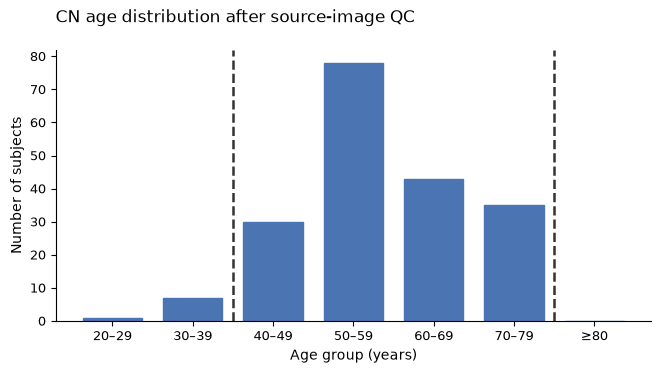

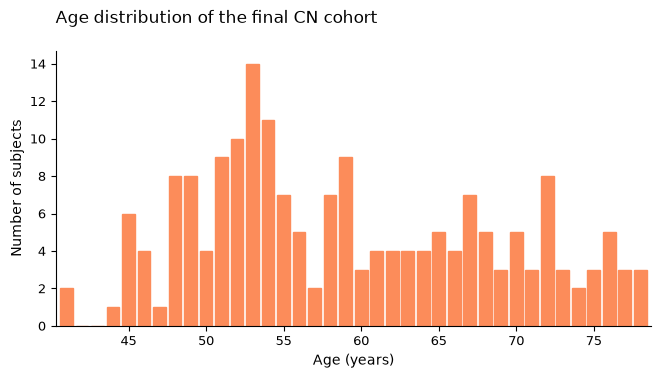

,cohort,n_subjects,minimum_age,maximum_age,mean_age,sd_age,median_age,q1_age,q3_age
0,CN subjects after source-image QC,194,28.0,78.0,58.061856,10.549478,56.0,51.0,67.0
1,"Final CN cohort, ages 40–79",186,41.0,78.0,59.112903,9.420687,58.0,52.0,67.0


In [31]:
# Source-image QC is applied first (196 to 194 CN participants), followed by the prespecified
# 40–79-year window, yielding the final 186-participant cohort.
cohort_audit = pd.read_csv(ROOT / "cohort_audit.csv", dtype={"subject_id": str})
all_cn = cohort_audit.loc[
    cohort_audit["diagnosis_at_scan"].eq("Normal") & cohort_audit["age"].notna()
].copy()
all_cn["age"] = all_cn["age"].astype(float)
SOURCE_IMAGE_EXCLUSIONS = ["D0271", "D0285"]
image_qc_cn = all_cn.loc[~all_cn["subject_id"].isin(SOURCE_IMAGE_EXCLUSIONS)].copy()
AGE_MIN, AGE_MAX = 40, 79
age_filtered_cn = image_qc_cn.loc[
    image_qc_cn["age"].between(AGE_MIN, AGE_MAX, inclusive="both")
].copy()
final_manifest = pd.read_csv(RESULT / "frozen_cohort_manifest.csv", dtype={"subject_id": str})
final_cn = final_manifest.loc[
    final_manifest["included"].astype(bool) & final_manifest["age"].notna()
].copy()
final_cn["age"] = final_cn["age"].astype(float)

assert len(all_cn) == 196 and len(image_qc_cn) == 194
assert len(age_filtered_cn) == 186 and len(final_cn) == 186
assert set(age_filtered_cn["subject_id"]) == set(final_cn["subject_id"])

age_group_order = ["20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "≥80"]
age_groups = pd.cut(
    image_qc_cn["age"], bins=[20, 30, 40, 50, 60, 70, 80, np.inf],
    labels=age_group_order, right=False, ordered=True,
)
age_group_counts = age_groups.value_counts(sort=False).reindex(age_group_order, fill_value=0)
x = np.arange(len(age_group_order))

fig, ax = plt.subplots(figsize=(7.09, 4.3))
ax.bar(x, age_group_counts.to_numpy(), width=0.74,
       color=COLORS["blue"], edgecolor=COLORS["blue"], linewidth=1.0)
ax.axvline(1.5, color=COLORS["dark_gray"], linewidth=1.8, linestyle="--")
ax.axvline(5.5, color=COLORS["dark_gray"], linewidth=1.8, linestyle="--")
ax.set_xticks(x, age_group_order)
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of subjects")
ax.set_title("CN age distribution after source-image QC", loc="left", pad=20)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_axis(ax)
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.17, top=0.80)
exported_figures.extend(export_figure(fig, "age_groups_cn_after_image_qc_with_boundaries"))
plt.show()

final_counts = final_cn.groupby("age").size().sort_index()
final_ages = np.arange(int(final_cn["age"].min()), int(final_cn["age"].max()) + 1)
fig, ax = plt.subplots(figsize=(7.09, 4.3))
ax.bar(final_ages, final_counts.reindex(final_ages, fill_value=0).to_numpy(), width=0.82,
       color=COLORS["orange"], edgecolor=COLORS["orange"], linewidth=1.0)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of subjects")
ax.set_title("Age distribution of the final CN cohort", loc="left", pad=20)
ax.set_xlim(final_ages.min() - 0.7, final_ages.max() + 0.7)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
clean_axis(ax)
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.16, top=0.80)
exported_figures.extend(export_figure(fig, "age_distribution_final_cn_186"))
plt.show()

def age_summary(frame, label):
    age = frame["age"].astype(float)
    return pd.DataFrame([{
        "cohort": label, "n_subjects": len(frame), "minimum_age": age.min(),
        "maximum_age": age.max(), "mean_age": age.mean(), "sd_age": age.std(ddof=1),
        "median_age": age.median(), "q1_age": age.quantile(0.25),
        "q3_age": age.quantile(0.75),
    }])

display(pd.concat([
    age_summary(image_qc_cn, "CN subjects after source-image QC"),
    age_summary(final_cn, "Final CN cohort, ages 40–79"),
], ignore_index=True))

## 3. OOF merge and integrity checks

In [32]:
assert oof_validation["status"] == "complete"
assert oof_validation["n_oof_predictions"] == 18_100_551
assert oof_validation["duplicate_keys"] == 0
assert oof_validation["missing_expected_keys"] == 0
assert oof_validation["extra_keys"] == 0
assert oof_validation["nonfinite_predictions"] == 0
assert oof_validation["gaussian_fallbacks"] == 0

availability = json.loads((OOF / "availability_rule.json").read_text())
invalid = pd.read_parquet(OOF / "invalid_availability_positions.parquet")
integrity_summary = pd.DataFrame([{
    "valid_oof_predictions": oof_validation["n_oof_predictions"],
    "invalid_subject_node_depth_positions": len(invalid),
    "availability_rule": availability["valid_if"],
    "response_imputation": availability["response_imputation"],
    "duplicate_keys": oof_validation["duplicate_keys"],
    "missing_expected_keys": oof_validation["missing_expected_keys"],
    "extra_keys": oof_validation["extra_keys"],
}])
display(integrity_summary)

,valid_oof_predictions,invalid_subject_node_depth_positions,availability_rule,response_imputation,duplicate_keys,missing_expected_keys,extra_keys
0,18100551,206871,response MD and node-local FreeSurfer thicknes...,False,0,0,0


## 4. Held-out calibration and participant-bootstrap uncertainty

In [33]:
display(overall.T.rename(columns={0: "Overall OOF"}))
display(bootstrap.query("scope == 'overall'")[[
    "metric", "estimate", "ci_lower", "ci_upper", "n_subjects", "n_bootstrap",
    "resampling_unit"
]])
display(by_age)
display(by_hemi)
display(by_depth.head())

,Overall OOF
n_predictions,18100551
mean_z,-0.0205
sd_z,1.00368
skewness,0.085699
excess_kurtosis,0.523788
coverage_50,0.497707
coverage_80,0.802967
coverage_90,0.903809
coverage_mae,0.003023
mean_log_likelihood,7.372208


,metric,estimate,ci_lower,ci_upper,n_subjects,n_bootstrap,resampling_unit
270,mean_z,-0.020500,-0.038960,-0.002027,186,10000,participant
271,sd_z,1.003680,0.983340,1.024962,186,10000,participant
272,coverage_50,0.497707,0.488647,0.506683,186,10000,participant
273,coverage_80,0.802967,0.793762,0.811789,186,10000,participant
274,coverage_90,0.903809,0.897000,0.910160,186,10000,participant
275,mean_log_likelihood,7.372208,7.344256,7.398218,186,10000,participant
276,fraction_abs_z_gt_2,0.043235,0.039322,0.047491,186,10000,participant
277,fraction_abs_z_gt_3,0.004263,0.003557,0.005066,186,10000,participant
278,fraction_abs_z_gt_4,0.000656,0.000517,0.000819,186,10000,participant
279,coverage_mae,0.003023,0.002046,0.009781,186,10000,participant


,scope,level,n_predictions,mean_z,sd_z,skewness,excess_kurtosis,coverage_50,coverage_80,coverage_90,coverage_mae,mean_log_likelihood,fraction_abs_z_gt_2,fraction_abs_z_gt_3,fraction_abs_z_gt_4,depth_index,depth_fraction
0,age_group,40–49,2920764,-0.017608,0.953634,0.076835,0.714265,0.522538,0.825562,0.918813,0.022304,7.450353,0.034796,0.002834,0.000435,NaN,NaN
1,age_group,50–59,7593264,-0.028739,0.955119,0.050798,0.399885,0.520577,0.825412,0.918966,0.021652,7.443998,0.034790,0.003100,0.000445,NaN,NaN
2,age_group,60–69,4180260,-0.044267,1.052111,0.088862,0.531240,0.470694,0.778848,0.888493,0.020655,7.304800,0.051561,0.005518,0.000857,NaN,NaN
3,age_group,70–79,3406263,0.024554,1.085517,0.124029,0.397280,0.458586,0.763160,0.875952,0.034101,7.227894,0.059076,0.006541,0.001071,NaN,NaN


,scope,level,n_predictions,mean_z,sd_z,skewness,excess_kurtosis,coverage_50,coverage_80,coverage_90,coverage_mae,mean_log_likelihood,fraction_abs_z_gt_2,fraction_abs_z_gt_3,fraction_abs_z_gt_4,depth_index,depth_fraction
0,hemisphere,lh,9046107,-0.020512,1.003930,0.096835,0.635751,0.497566,0.803390,0.904162,0.003329,7.376122,0.043152,0.004342,0.000695,NaN,NaN
1,hemisphere,rh,9054444,-0.020489,1.003431,0.074556,0.411706,0.497848,0.802546,0.903456,0.002718,7.368298,0.043317,0.004183,0.000617,NaN,NaN


,scope,level,n_predictions,mean_z,sd_z,skewness,excess_kurtosis,coverage_50,coverage_80,coverage_90,coverage_mae,mean_log_likelihood,fraction_abs_z_gt_2,fraction_abs_z_gt_3,fraction_abs_z_gt_4,depth_index,depth_fraction
0,depth,0,861931,-0.020430,0.992012,-0.014531,0.136379,0.491148,0.803652,0.908725,0.007076,6.700655,0.038136,0.003194,0.000490,0.0,0.00
1,depth,1,861931,-0.021494,0.992174,0.007296,0.075618,0.487801,0.802926,0.908869,0.007998,6.768458,0.037698,0.002998,0.000374,1.0,0.05
2,depth,10,861931,-0.020474,1.004936,0.095810,0.275629,0.498329,0.800088,0.901036,0.000932,7.451323,0.044422,0.003869,0.000514,10.0,0.50
3,depth,11,861931,-0.020371,1.006260,0.099600,0.428965,0.501484,0.801402,0.900744,0.001210,7.520613,0.045359,0.004275,0.000589,11.0,0.55
4,depth,12,861931,-0.020202,1.007038,0.099878,0.588761,0.504777,0.803485,0.900649,0.002970,7.583102,0.046409,0.004602,0.000679,12.0,0.60


In [34]:
worst = pd.read_csv(OOF / "worst_calibrated_node_depth.csv")
left_para = pd.read_csv(OOF / "left_parahippocampal_calibration.csv")
display(Markdown("### Diagnostic locations (not exclusion criteria)"))
display(worst.head(20))
display(left_para.sort_values("composite_calibration_rank", ascending=False).head(20))

### Diagnostic locations (not exclusion criteria)

,node_index,hemisphere,ico_node_id,fsaverage_vertex_id,dk_label_id,dk_label_name,depth_index,depth_fraction,n_predictions,mean_z,...,fraction_abs_z_gt_4,max_abs_z,qq_rmse,abs_mean_z,abs_sd_z_minus_1,rank_pct_coverage_mae,rank_pct_qq_rmse,rank_pct_abs_mean_z,rank_pct_abs_sd_z_minus_1,composite_calibration_rank
0,3537,rh,1251,901,2,caudalanteriorcingulate,2,0.10,17,0.245563,...,0.058824,10.269655,1.091099,0.245563,1.713313,0.999599,1.000000,0.999919,1.000000,0.999879
1,3575,rh,1359,913,23,posteriorcingulate,0,0.00,21,-0.183583,...,0.000000,3.878223,0.559919,0.183583,0.450707,0.999837,0.999909,0.999756,0.999776,0.999820
2,3575,rh,1359,913,23,posteriorcingulate,13,0.65,21,0.125612,...,0.047619,8.350880,0.782154,0.125612,1.123766,0.999380,0.999949,0.999522,0.999959,0.999703
3,3575,rh,1359,913,23,posteriorcingulate,2,0.10,21,-0.264638,...,0.000000,3.473030,0.415869,0.264638,0.332123,0.999802,0.999563,0.999970,0.999451,0.999696
4,3575,rh,1359,913,23,posteriorcingulate,3,0.15,21,-0.256961,...,0.000000,3.321145,0.362478,0.256961,0.305975,0.999837,0.999208,0.999949,0.999340,0.999583
5,3537,rh,1251,901,2,caudalanteriorcingulate,7,0.35,17,-0.303922,...,0.000000,3.549605,0.341966,0.303922,0.284819,0.999837,0.999035,1.000000,0.999228,0.999525
6,3537,rh,1251,901,2,caudalanteriorcingulate,4,0.20,17,-0.210738,...,0.000000,3.149676,0.326296,0.210738,0.273076,0.999599,0.998882,0.999888,0.999096,0.999366
7,3575,rh,1359,913,23,posteriorcingulate,6,0.30,21,-0.191676,...,0.000000,3.386315,0.306403,0.191676,0.253629,0.999970,0.998608,0.999797,0.998964,0.999335
8,3575,rh,1359,913,23,posteriorcingulate,1,0.05,21,-0.291010,...,0.000000,2.951162,0.424201,0.291010,0.173212,0.999802,0.999634,0.999990,0.997633,0.999265
9,3537,rh,1251,901,2,caudalanteriorcingulate,6,0.30,17,-0.261087,...,0.000000,3.031139,0.299721,0.261087,0.221242,0.999837,0.998425,0.999959,0.998628,0.999213


,node_index,hemisphere,ico_node_id,fsaverage_vertex_id,dk_label_id,dk_label_name,depth_index,depth_fraction,n_predictions,mean_z,...,fraction_abs_z_gt_4,max_abs_z,qq_rmse,abs_mean_z,abs_sd_z_minus_1,rank_pct_coverage_mae,rank_pct_qq_rmse,rank_pct_abs_mean_z,rank_pct_abs_sd_z_minus_1,composite_calibration_rank
230,2292,lh,2458,1799,16,parahippocampal,20,1.00,186,0.033100,...,0.005376,14.019454,0.422058,0.033100,0.402295,0.928419,0.999604,0.863940,0.999685,0.947912
207,2291,lh,2457,1798,16,parahippocampal,18,0.90,183,-0.035865,...,0.005464,5.959324,0.171821,0.035865,0.035271,0.981311,0.978766,0.894053,0.900444,0.938644
459,2303,lh,2475,2560,16,parahippocampal,18,0.90,184,-0.052742,...,0.005435,5.481452,0.129958,0.052742,0.067691,0.800746,0.888557,0.980046,0.980310,0.912415
61,578,lh,619,360,16,parahippocampal,19,0.95,186,0.083824,...,0.005376,21.017212,0.681381,0.083824,0.821595,0.601344,0.999939,0.998689,0.999929,0.899975
62,578,lh,619,360,16,parahippocampal,20,1.00,186,0.113533,...,0.005376,24.809607,0.814465,0.113533,1.067143,0.589676,0.999959,0.999299,0.999949,0.897221
267,2294,lh,2460,1437,16,parahippocampal,15,0.75,186,-0.024708,...,0.005376,4.275543,0.169793,0.024708,0.050717,0.957923,0.977019,0.690024,0.958121,0.895772
268,2294,lh,2460,1437,16,parahippocampal,16,0.80,186,-0.023451,...,0.010753,4.503135,0.181318,0.023451,0.065716,0.948398,0.985085,0.649984,0.978796,0.890566
223,2292,lh,2458,1799,16,parahippocampal,13,0.65,186,-0.022042,...,0.005376,5.553579,0.178658,0.022042,0.077582,0.974880,0.983622,0.599185,0.985969,0.885914
229,2292,lh,2458,1799,16,parahippocampal,19,0.95,186,0.022945,...,0.005376,12.342228,0.351509,0.022945,0.312211,0.886825,0.999086,0.631981,0.999390,0.879320
209,2291,lh,2457,1798,16,parahippocampal,20,1.00,183,-0.026576,...,0.005464,6.397044,0.177425,0.026576,0.052423,0.815935,0.982871,0.742571,0.961626,0.875751


### Regional Gaussian M2 and Warped M2 OOF z-score distributions

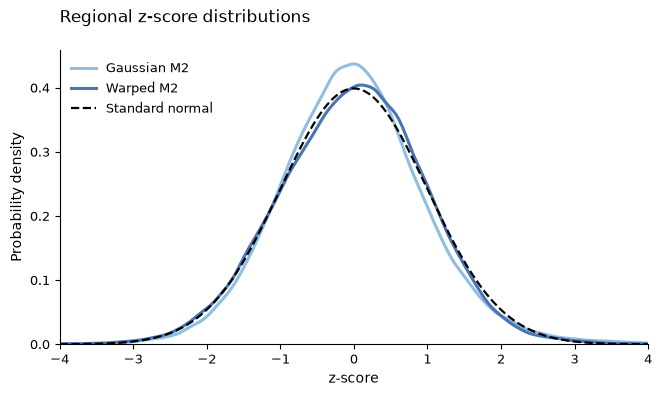

,Gaussian M2,Warped M2
Skewness,0.427425,-0.001229
Excess kurtosis,2.506152,0.834991
Fraction |z| > 3,0.008245,0.005237


In [35]:
# Frozen 186-participant regional OOF results; no model is refitted here.
REGIONAL = ROOT / "regional_warped_m2_186"
gaussian_path = REGIONAL / "oof_predictions_gaussian_M0_M3_long.parquet"
warped_path = REGIONAL / "oof_predictions_warped_M2_long.parquet"
regional_keys = ["subject_id", "outer_fold", "region_index", "hemisphere",
                 "dk_label_id", "depth_index"]
gaussian_oof = pd.read_parquet(
    gaussian_path, columns=regional_keys + ["model", "observed_md", "z"]
).query("model == 'M2'").drop(columns="model")
warped_oof = pd.read_parquet(
    warped_path, columns=regional_keys + ["observed_md", "z"]
)
regional_matched = gaussian_oof.merge(
    warped_oof, on=regional_keys, how="inner", validate="one_to_one",
    suffixes=("_gaussian", "_warped"),
)
assert len(regional_matched) == len(gaussian_oof) == len(warped_oof) == 265_608
assert regional_matched["subject_id"].nunique() == 186
assert np.allclose(regional_matched["observed_md_gaussian"],
                   regional_matched["observed_md_warped"], rtol=0, atol=1e-12)

z_gaussian = regional_matched["z_gaussian"].to_numpy(float)
z_warped = regional_matched["z_warped"].to_numpy(float)
def regional_z_statistics(z):
    return {
        "Skewness": stats.skew(z, bias=True),
        "Excess kurtosis": stats.kurtosis(z, fisher=True, bias=True),
        "Fraction |z| > 3": np.mean(np.abs(z) > 3),
    }

regional_z_stats = pd.DataFrame({
    "Gaussian M2": regional_z_statistics(z_gaussian),
    "Warped M2": regional_z_statistics(z_warped),
})
density_grid = np.linspace(-4, 4, 801)
gaussian_density = stats.gaussian_kde(z_gaussian, bw_method="scott")(density_grid)
warped_density = stats.gaussian_kde(z_warped, bw_method="scott")(density_grid)
normal_density = stats.norm.pdf(density_grid)

fig, ax = plt.subplots(figsize=(7.09, 4.6))
ax.plot(density_grid, gaussian_density, color=COLORS["light_blue"], linewidth=2.2,
        label="Gaussian M2")
ax.plot(density_grid, warped_density, color=COLORS["blue"], linewidth=2.2,
        label="Warped M2")
ax.plot(density_grid, normal_density, color="black", linewidth=1.6, linestyle="--",
        label="Standard normal")
ax.set_xlim(-4, 4)
ax.set_ylim(bottom=0)
ax.set_xlabel("z-score")
ax.set_ylabel("Probability density")
ax.set_title("Regional z-score distributions", loc="left", pad=20)
ax.legend(frameon=False, loc="upper left")
clean_axis(ax)
fig.subplots_adjust(left=0.14, right=0.97, bottom=0.16, top=0.80)
exported_figures.extend(export_figure(fig, "regional_gaussian_vs_warped_oof_z_distribution"))
plt.show()
display(regional_z_stats)

### English diagnostic figures

The Q–Q plot uses 999 equally spaced probabilities from 0.001 through 0.999 and a fixed `y=x`
reference line; it therefore does not assess more extreme tails. The 95% confidence intervals and
bands use 10,000 subject-bootstrap resamples, retaining all available node × depth predictions for
each sampled participant.

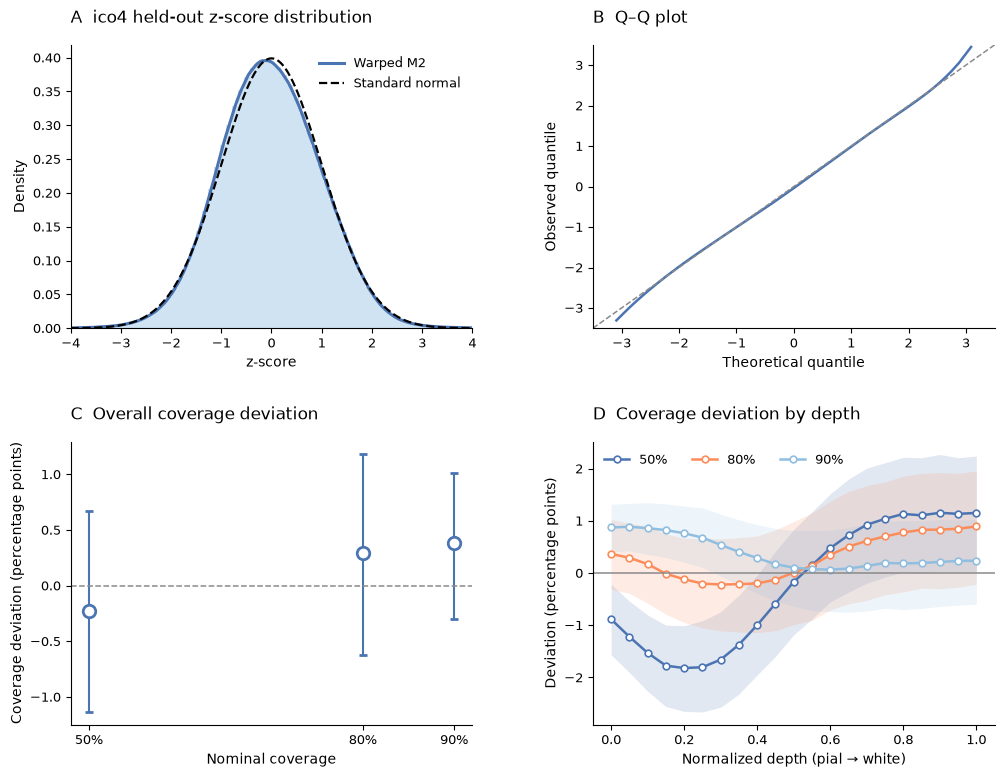

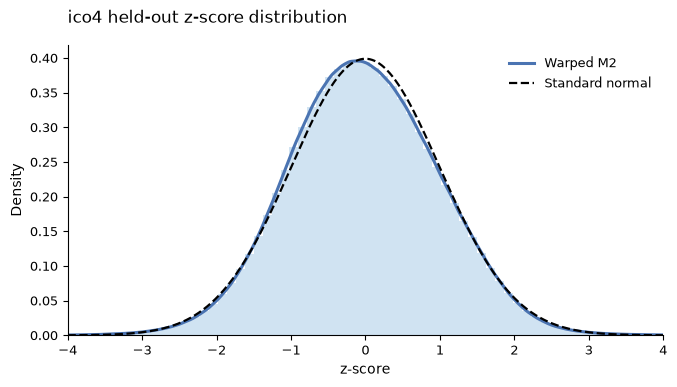

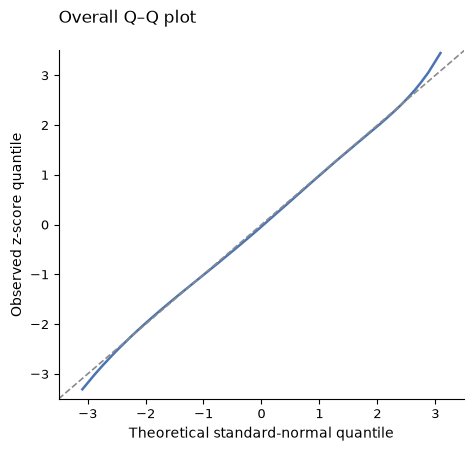

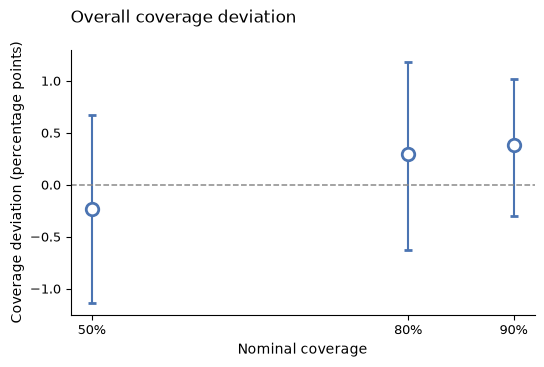

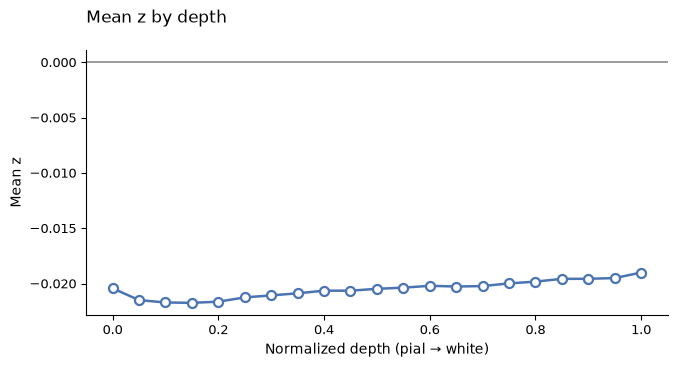

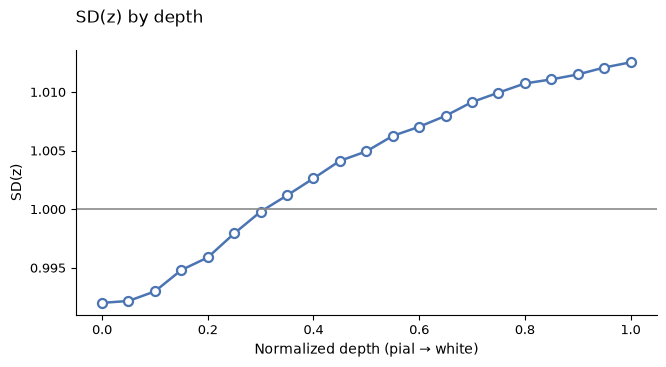

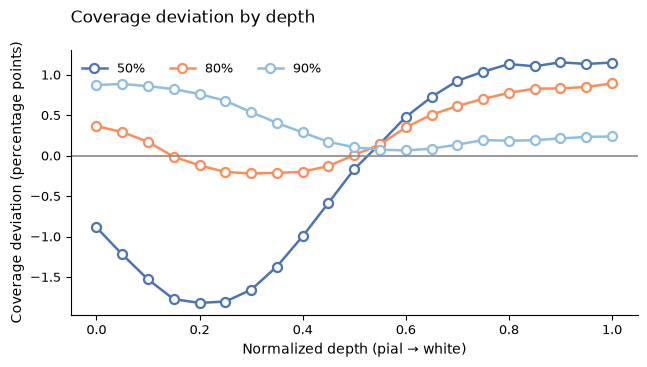

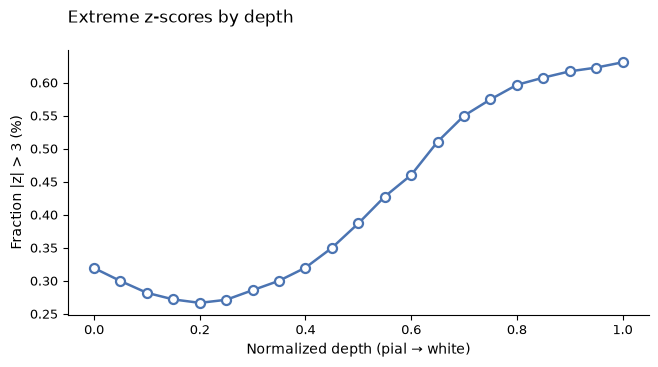

In [36]:
# Load the complete held-out z-score vector once; every diagnostic figure is drawn in this cell.
z_values = np.load(OOF / "all_oof_z.npy", mmap_mode="r")
overall_row = overall.iloc[0]
depth_table = by_depth.sort_values("depth_index").copy()
depth_x = depth_table["depth_fraction"].to_numpy(float)
overall_ci = bootstrap.query("scope == 'overall'").set_index("metric")
depth_ci = bootstrap.query("scope == 'depth'").copy()
depth_ci["depth_index"] = depth_ci["level"].astype(int)

# Empirical density based on all valid z-scores; only the display is restricted to [-4, 4].
density_bin_width = 0.02
density_edges = np.arange(
    np.floor(float(z_values.min()) / density_bin_width) * density_bin_width,
    np.ceil(float(z_values.max()) / density_bin_width) * density_bin_width + 1.1 * density_bin_width,
    density_bin_width,
)
density_counts, _ = np.histogram(z_values, bins=density_edges)
density_centers = (density_edges[:-1] + density_edges[1:]) / 2
density_raw = density_counts / (len(z_values) * density_bin_width)
scott_bandwidth = float(overall_row["sd_z"]) * len(z_values) ** (-1 / 5)
empirical_density = gaussian_filter1d(
    density_raw.astype(float), sigma=scott_bandwidth / density_bin_width, mode="constant"
)
density_display = (density_centers >= -4) & (density_centers <= 4)
hist_bin_width = 0.12
hist_edges = np.arange(-4.02, 4.02 + hist_bin_width, hist_bin_width)
hist_counts, _ = np.histogram(z_values, bins=hist_edges)
hist_heights = hist_counts / (len(z_values) * hist_bin_width)
normal_x = np.linspace(-4, 4, 1000)

def draw_z_distribution(ax, panel_title=None):
    ax.bar(hist_edges[:-1], hist_heights, width=hist_bin_width, align="edge",
           color=COLORS["light_blue"], alpha=0.42, edgecolor="none")
    ax.plot(density_centers[density_display], empirical_density[density_display],
            color=COLORS["blue"], linewidth=2.2, label="Warped M2")
    ax.plot(normal_x, stats.norm.pdf(normal_x), color="black", linewidth=1.6,
            linestyle="--", label="Standard normal")
    ax.set_xlim(-4, 4)
    ax.set_xticks(np.arange(-4, 5, 1))
    ax.set_xlabel("z-score")
    ax.set_ylabel("Density")
    if panel_title:
        ax.set_title(panel_title, loc="left", pad=16)
    ax.legend(frameon=False, loc="upper right")
    clean_axis(ax)

qq_grid = np.linspace(0.001, 0.999, 999)
observed_q = np.quantile(z_values, qq_grid)
expected_q = stats.norm.ppf(qq_grid)
qq_limits = (-3.5, 3.5)
nominal = np.array([0.50, 0.80, 0.90])
observed = np.array([overall_row[f"coverage_{int(level * 100)}"] for level in nominal])
coverage_deviation = 100 * (observed - nominal)
coverage_low = np.array([
    100 * (overall_ci.loc[f"coverage_{int(level * 100)}", "ci_lower"] - level)
    for level in nominal
])
coverage_high = np.array([
    100 * (overall_ci.loc[f"coverage_{int(level * 100)}", "ci_upper"] - level)
    for level in nominal
])
coverage_yerr = np.vstack((coverage_deviation - coverage_low,
                           coverage_high - coverage_deviation))

# Combined four-panel diagnostic summary.
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
draw_z_distribution(axes[0, 0], "A  ico4 held-out z-score distribution")
axes[0, 1].plot(expected_q, observed_q, color=COLORS["blue"], linewidth=LINE_WIDTH)
axes[0, 1].plot(qq_limits, qq_limits, color=COLORS["gray"], linestyle="--", linewidth=1.1)
axes[0, 1].set(xlim=qq_limits, ylim=qq_limits,
               xlabel="Theoretical quantile", ylabel="Observed quantile")
axes[0, 1].set_title("B  Q–Q plot", loc="left", pad=16)
clean_axis(axes[0, 1])
axes[1, 0].errorbar(
    100 * nominal, coverage_deviation, yerr=coverage_yerr, linestyle="none", marker="o",
    markersize=POINT_SIZE, markerfacecolor="white", markeredgecolor=COLORS["blue"],
    markeredgewidth=POINT_EDGE_WIDTH, ecolor=COLORS["blue"], elinewidth=1.5,
    capsize=3, capthick=1.2,
)
axes[1, 0].axhline(0, color=COLORS["gray"], linestyle="--", linewidth=1.1)
axes[1, 0].set_xticks(100 * nominal, ["50%", "80%", "90%"])
axes[1, 0].set_xlabel("Nominal coverage")
axes[1, 0].set_ylabel("Coverage deviation (percentage points)")
axes[1, 0].set_title("C  Overall coverage deviation", loc="left", pad=16)
clean_axis(axes[1, 0])
for level, color in zip((50, 80, 90),
                        (COLORS["blue"], COLORS["orange"], COLORS["light_blue"])):
    deviation = 100 * (depth_table[f"coverage_{level}"] - level / 100)
    metric_name = f"coverage_{level}"
    level_ci = depth_ci.query("metric == @metric_name").sort_values("depth_index")
    ci_low = 100 * (level_ci["ci_lower"].to_numpy() - level / 100)
    ci_high = 100 * (level_ci["ci_upper"].to_numpy() - level / 100)
    axes[1, 1].fill_between(depth_x, ci_low, ci_high, color=color, alpha=0.16, linewidth=0)
    axes[1, 1].plot(depth_x, deviation, color=color, linewidth=LINE_WIDTH, marker="o",
                    markersize=4.8, markerfacecolor="white", markeredgecolor=color,
                    markeredgewidth=1.2, label=f"{level}%")
axes[1, 1].axhline(0, color=COLORS["gray"], linewidth=1.1)
axes[1, 1].set_xlabel("Normalized depth (pial → white)")
axes[1, 1].set_ylabel("Deviation (percentage points)")
axes[1, 1].set_title("D  Coverage deviation by depth", loc="left", pad=16)
axes[1, 1].legend(frameon=False, ncol=3)
clean_axis(axes[1, 1])
fig.subplots_adjust(left=0.10, right=0.98, bottom=0.09, top=0.94,
                    wspace=0.30, hspace=0.40)
exported_figures.extend(export_figure(fig, "ico4_diagnostic_summary"))
plt.show()

# Separate editable versions of all diagnostic panels.
fig, ax = plt.subplots(figsize=(7.09, 4.4))
draw_z_distribution(ax, "ico4 held-out z-score distribution")
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.16, top=0.82)
exported_figures.extend(export_figure(fig, "ico4_heldout_z_distribution"))
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot(expected_q, observed_q, color=COLORS["blue"], linewidth=LINE_WIDTH)
ax.plot(qq_limits, qq_limits, color=COLORS["gray"], linestyle="--", linewidth=1.2)
ax.set(xlim=qq_limits, ylim=qq_limits,
       xlabel="Theoretical standard-normal quantile", ylabel="Observed z-score quantile")
ax.set_title("Overall Q–Q plot", loc="left", pad=20)
clean_axis(ax)
fig.subplots_adjust(left=0.18, right=0.96, bottom=0.15, top=0.82)
exported_figures.extend(export_figure(fig, "oof_qq_001_999"))
plt.show()

fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.errorbar(100 * nominal, coverage_deviation, yerr=coverage_yerr, linestyle="none", marker="o",
            markersize=POINT_SIZE, markerfacecolor="white", markeredgecolor=COLORS["blue"],
            markeredgewidth=POINT_EDGE_WIDTH, ecolor=COLORS["blue"], elinewidth=1.5,
            capsize=3, capthick=1.2)
ax.axhline(0, color=COLORS["gray"], linestyle="--", linewidth=1.1)
ax.set_xticks(100 * nominal, ["50%", "80%", "90%"])
ax.set_xlabel("Nominal coverage")
ax.set_ylabel("Coverage deviation (percentage points)")
ax.set_title("Overall coverage deviation", loc="left", pad=20)
clean_axis(ax)
fig.subplots_adjust(left=0.17, right=0.97, bottom=0.17, top=0.80)
exported_figures.extend(export_figure(fig, "oof_observed_vs_nominal_coverage"))
plt.show()

def plot_depth_metric(values, ylabel, title, stem, reference=None):
    fig, ax = plt.subplots(figsize=(7.09, 4.2))
    ax.plot(depth_x, values, color=COLORS["blue"], linewidth=LINE_WIDTH, marker="o",
            markersize=6.5, markerfacecolor="white", markeredgecolor=COLORS["blue"],
            markeredgewidth=1.6)
    if reference is not None:
        ax.axhline(reference, color=COLORS["gray"], linewidth=1.2)
    ax.set_xlabel("Normalized depth (pial → white)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", pad=20)
    clean_axis(ax)
    fig.subplots_adjust(left=0.15, right=0.97, bottom=0.17, top=0.80)
    exported_figures.extend(export_figure(fig, stem))
    plt.show()

plot_depth_metric(depth_table["mean_z"], "Mean z", "Mean z by depth",
                  "oof_depth_mean_z", reference=0)
plot_depth_metric(depth_table["sd_z"], "SD(z)", "SD(z) by depth",
                  "oof_depth_sd_z", reference=1)

fig, ax = plt.subplots(figsize=(7.09, 4.2))
for level, color in zip((50, 80, 90),
                        (COLORS["blue"], COLORS["orange"], COLORS["light_blue"])):
    deviation = 100 * (depth_table[f"coverage_{level}"] - level / 100)
    ax.plot(depth_x, deviation, color=color, linewidth=LINE_WIDTH, marker="o",
            markersize=6.5, markerfacecolor="white", markeredgecolor=color,
            markeredgewidth=1.6, label=f"{level}%")
ax.axhline(0, color=COLORS["gray"], linewidth=1.2)
ax.set_xlabel("Normalized depth (pial → white)")
ax.set_ylabel("Coverage deviation (percentage points)")
ax.set_title("Coverage deviation by depth", loc="left", pad=20)
ax.legend(frameon=False, ncol=3)
clean_axis(ax)
fig.subplots_adjust(left=0.17, right=0.97, bottom=0.17, top=0.80)
exported_figures.extend(export_figure(fig, "oof_depth_coverage_deviation"))
plt.show()

plot_depth_metric(100 * depth_table["fraction_abs_z_gt_3"],
                  "Fraction |z| > 3 (%)", "Extreme z-scores by depth",
                  "oof_depth_fraction_abs_z_gt_3")

## 5. Full-cohort model and recoverable parameter index

In [37]:
assert full_validation["status"] == "complete"
assert full_validation["successful_models"] == 4687 * 21
assert full_validation["failed_models"] == 0
assert full_validation["restored_models_checked"] == 4687 * 21
parameter_index = pd.read_parquet(FULL / "parameter_file_index.parquet")
centile_index = pd.read_parquet(FULL / "centile_file_index.parquet")
display(pd.DataFrame([full_validation]).T.rename(columns={0: "Full-cohort validation"}))
display(parameter_index.head())
display(centile_index.head())

,Full-cohort validation
status,complete
cohort_n,186
n_nodes,4687
n_depths,21
expected_models,98427
successful_models,98427
failed_models,0
warning_models,3639
restored_models_checked,98427
centile_rows,6299328


,relative_path,node_index,hemisphere,vertex_chunk,n_models,n_warnings
0,full_models/parameters/hemisphere=lh/vertex_ch...,0,lh,0,21,0
1,full_models/parameters/hemisphere=lh/vertex_ch...,1,lh,0,21,0
2,full_models/parameters/hemisphere=lh/vertex_ch...,2,lh,0,21,0
3,full_models/parameters/hemisphere=lh/vertex_ch...,3,lh,0,21,2
4,full_models/parameters/hemisphere=lh/vertex_ch...,4,lh,0,21,0


,relative_path,node_index,hemisphere,vertex_chunk,n_rows,age_min,age_max,n_depths,n_sex_codes
0,full_models/centiles/hemisphere=lh/vertex_chun...,0,lh,0,1344,45.0,76.0,21,2
1,full_models/centiles/hemisphere=lh/vertex_chun...,1,lh,0,1344,45.0,76.0,21,2
2,full_models/centiles/hemisphere=lh/vertex_chun...,2,lh,0,1344,45.0,76.0,21,2
3,full_models/centiles/hemisphere=lh/vertex_chun...,3,lh,0,1344,45.0,76.0,21,2
4,full_models/centiles/hemisphere=lh/vertex_chun...,4,lh,0,1344,45.0,76.0,21,2


## 6. Three prespecified representative left-hemisphere nodes

We selected one representative ico4 node from each of three prespecified left-hemisphere DK
regions: precentral, superior frontal, and parahippocampal. Eligible nodes were required to have
valid MD at all 21 depths and complete local thickness data for all 186 CN participants. Within
each region, we selected the eligible node with the smallest mean surface graph-geodesic distance
to the other eligible nodes. The locator plots show the selected nodes on the template cortical
surface.

,selection_rule,geometry_method,geometry_is_approximation,geometry_subject,hemisphere,dk_label_name,node_index,ico_node_id,fsaverage_vertex_id,n_eligible_complete_nodes,...,oof_n_subjects,oof_n_observations,oof_mean_z,oof_sd_z,oof_coverage_50,oof_coverage_80,oof_coverage_90,oof_fraction_abs_z_gt_3,previous_parahippocampal_node_index,previous_rule_matches_geodesic_medoid
0,Complete MD at all 21 depths and complete loca...,exact shortest paths on canonical fsaverage lh...,False,fsaverage,lh,precentral,1002,1056,844,155,...,186,3906,-0.037315,1.003628,0.498976,0.802867,0.901434,0.004864,NaN,NaN
1,Complete MD at all 21 depths and complete loca...,exact shortest paths on canonical fsaverage lh...,False,fsaverage,lh,superiorfrontal,982,1036,2143,177,...,186,3906,-0.031695,0.988962,0.498208,0.791859,0.904506,0.001792,NaN,NaN
2,Complete MD at all 21 depths and complete loca...,exact shortest paths on canonical fsaverage lh...,False,fsaverage,lh,parahippocampal,578,619,360,8,...,186,3906,0.003376,1.165406,0.560932,0.825397,0.904250,0.014849,2294.0,False


TypeError: _plot_surf() got an unexpected keyword argument 'threshould'

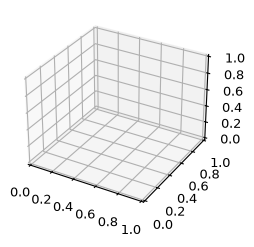

In [45]:
TARGET_REGIONS = ["precentral", "superiorfrontal", "parahippocampal"]
REGION_TITLES = {"precentral": "Precentral", "superiorfrontal": "Superior frontal",
                 "parahippocampal": "Parahippocampal"}
MAIN_DEPTHS = [4, 10, 16]
MAIN_SEX_CODE, SUPPLEMENT_SEX_CODE = 2, 1
representative_nodes = pd.read_csv(
    NOTEBOOK_FIGURE_DIR / "figure6a_representative_node_information.csv")
representative_predictions = pd.read_parquet(
    NOTEBOOK_FIGURE_DIR / "figure6a_representative_node_21depth_predictions.parquet")
display(representative_nodes)

# Canonical fsaverage inflated-surface locator. Blue is the full DK label; red marks the selected
# vertex and its 7-mm white-surface neighbourhood. Precentral is lateral; the other views are medial.
fsaverage_candidates = [
    Path("/home/apps/freesurfer/subjects/fsaverage"),
    Path(os.environ["SUBJECTS_DIR"]) / "fsaverage" if "SUBJECTS_DIR" in os.environ else None,
    Path(os.environ["FREESURFER_HOME"]) / "subjects" / "fsaverage"
    if "FREESURFER_HOME" in os.environ else None,
]
FSAVERAGE = next((path for path in fsaverage_candidates
                  if path is not None and (path / "surf" / "lh.white").is_file()), None)
if FSAVERAGE is None:
    raise FileNotFoundError("A complete FreeSurfer fsaverage installation is required.")
white_xyz, white_faces = fsio.read_geometry(FSAVERAGE / "surf" / "lh.white")
inflated_xyz, inflated_faces = fsio.read_geometry(FSAVERAGE / "surf" / "lh.inflated")
sulc_values = fsio.read_morph_data(FSAVERAGE / "surf" / "lh.sulc")
aparc_labels, _, aparc_names = fsio.read_annot(FSAVERAGE / "label" / "lh.aparc.annot")
mesh_edges = np.vstack((white_faces[:, [0, 1]], white_faces[:, [1, 2]],
                        white_faces[:, [2, 0]]))
mesh_weights = np.linalg.norm(
    white_xyz[mesh_edges[:, 0]] - white_xyz[mesh_edges[:, 1]], axis=1)
surface_graph = coo_matrix((np.r_[mesh_weights, mesh_weights],
                            (np.r_[mesh_edges[:, 0], mesh_edges[:, 1]],
                             np.r_[mesh_edges[:, 1], mesh_edges[:, 0]])),
                           shape=(len(white_xyz), len(white_xyz))).tocsr()
aparc_name_to_label = {name.decode("utf-8"): index for index, name in enumerate(aparc_names)}

fig = plt.figure(figsize=(9.0, 3.0))
for panel, region in enumerate(TARGET_REGIONS, start=1):
    ax = fig.add_subplot(1, 3, panel, projection="3d")
    selected_vertex = int(representative_nodes.query(
        "dk_label_name == @region")["fsaverage_vertex_id"].iloc[0])
    roi_map = np.zeros(len(inflated_xyz), dtype=float)
    roi_map[aparc_labels == aparc_name_to_label[region]] = 1
    selected_distance = dijkstra(surface_graph, directed=False,
                                 indices=selected_vertex, limit=7.0)
    roi_map[np.isfinite(selected_distance) & (selected_distance <= 7.0)] = 2
    plotting.plot_surf_roi(
        (inflated_xyz, inflated_faces), roi_map=roi_map, bg_map=sulc_values,
        hemi="left", view="lateral" if region == "precentral" else "medial",
        cmap=ListedColormap([COLORS["light_blue"], COLORS["red"]]),
        threshold=0.5,
        vmin=1, vmax=2, colorbar=False, axes=ax, figure=fig,
        avg_method="max",
    )
    ax.set_title(f"{REGION_TITLES[region]}\nvertex {selected_vertex}", fontsize=11, pad=4)
fig.tight_layout(pad=0.5)
exported_figures.extend(export_figure(fig, "figure6a_representative_node_locations"))
plt.show()

### Age-conditioned centile curves

Age-conditioned centile curves were generated using the full-cohort Warped M2 models. For
prediction, thickness was fixed at the corresponding node-local median among the 186 CN
participants, and sex was set separately to categories 1 and 2 using the same fitted model. The
curves show predicted MD medians and 5th–95th percentile ranges at normalized depths 0.20, 0.50,
and 0.80.

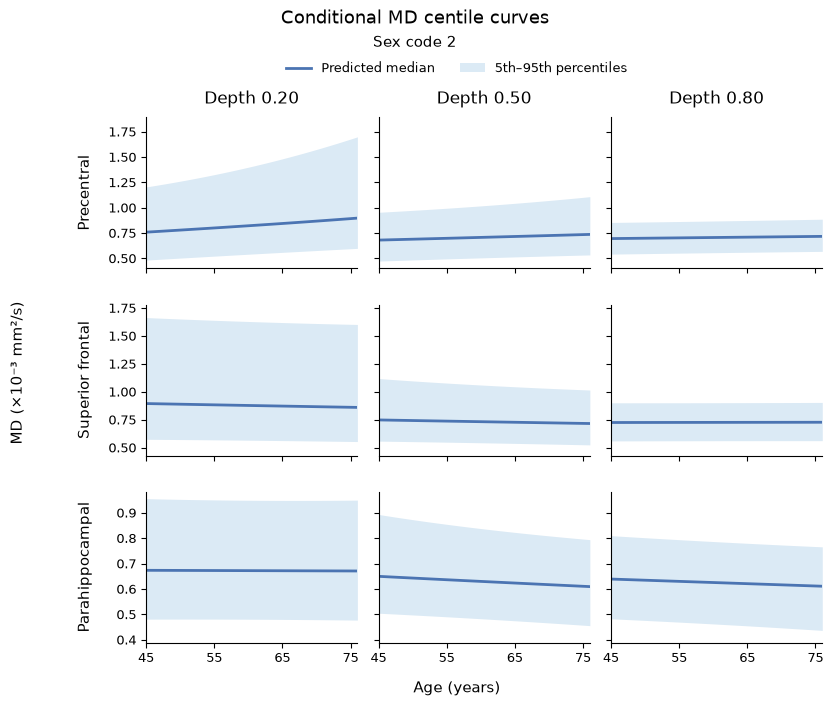

In [39]:
# A single row-specific y range is used across both sex-code figures for direct comparison.
REGION_YLIMS = {}
for region in TARGET_REGIONS:
    range_data = representative_predictions.query(
        "dk_label_name == @region and depth_index in @MAIN_DEPTHS")
    ymin = 1e3 * range_data["p05_md"].min()
    ymax = 1e3 * range_data["p95_md"].max()
    pad = 0.05 * (ymax - ymin)
    REGION_YLIMS[region] = (ymin - pad, ymax + pad)

def plot_representative_grid(sex_code, stem):
    fig, axes = plt.subplots(3, 3, figsize=(8.4, 7.1), sharex=True)
    for row, region in enumerate(TARGET_REGIONS):
        data = representative_predictions.query(
            "dk_label_name == @region and sex_code == @sex_code and depth_index in @MAIN_DEPTHS")
        for col, depth in enumerate(MAIN_DEPTHS):
            ax = axes[row, col]
            curve = data.query("depth_index == @depth").sort_values("age")
            age = curve["age"].to_numpy(float)
            p05, p50, p95 = [
                1e3 * curve[column].to_numpy(float)
                for column in ("p05_md", "p50_md", "p95_md")
            ]
            ax.fill_between(age, p05, p95, color=COLORS["light_blue"], alpha=0.32,
                            linewidth=0, label="5th–95th percentiles")
            ax.plot(age, p50, color=COLORS["blue"], linewidth=2.0,
                    label="Predicted median")
            ax.set(xlim=(45, 76), ylim=REGION_YLIMS[region])
            ax.set_xticks([45, 55, 65, 75])
            if row == 0:
                ax.set_title(f"Depth {depth / 20:.2f}", pad=10)
            if col > 0:
                ax.tick_params(axis="y", labelleft=False)
            clean_axis(ax)
        axes[row, 0].annotate(
            REGION_TITLES[region], xy=(-0.29, 0.5), xycoords="axes fraction",
            rotation=90, ha="center", va="center", fontsize=11)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], frameon=False, ncol=2,
               loc="upper center", bbox_to_anchor=(0.55, 0.935))
    fig.suptitle("Conditional MD centile curves", y=0.992, fontsize=13)
    fig.text(0.5, 0.955, f"Sex code {sex_code}", ha="center", va="top", fontsize=10.5)
    fig.supxlabel("Age (years)", x=0.55, y=0.025, fontsize=11)
    fig.supylabel("MD (×10⁻³ mm²/s)", x=0.018, y=0.48, fontsize=11)
    fig.subplots_adjust(left=0.18, right=0.985, bottom=0.10, top=0.84,
                        wspace=0.10, hspace=0.24)
    exported_figures.extend(export_figure(fig, stem))
    plt.show()

plot_representative_grid(MAIN_SEX_CODE,
                         "figure6a_representative_nodes_sex_code_2")

### Interpretation and sex-code supplement

The overall patterns were similar for both sex categories. Predicted MD increased with age at the
representative precentral node, with a larger increase at the outer depth. At the superior frontal
node, predicted MD decreased slightly at the outer and middle depths and remained relatively
stable at the inner depth. At the parahippocampal node, predicted MD remained relatively stable at
the outer depth and decreased at the middle and inner depths. The outer depths of the precentral
and superior frontal nodes also had wider central 90% prediction ranges, indicating greater
conditional interindividual variability at these locations.

The representative nodes from different regions showed different predicted age-curve patterns,
and age associations within a given node also varied with cortical depth.

**Supplement: sex code 1**

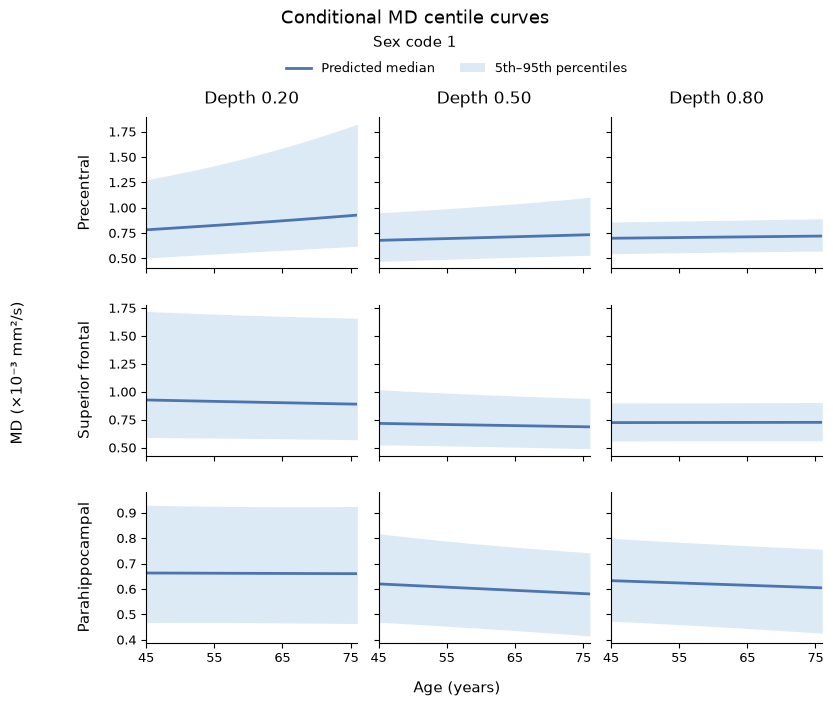

In [40]:
display(Markdown("**Supplement: sex code 1**"))
plot_representative_grid(SUPPLEMENT_SEX_CODE,
                         "figure6a_representative_nodes_sex_code_1_supplement")

## 7. Figure 6C: depth-stratified standardized age association

,item,value
0,Frozen estimand,equal-weight mean across the same frozen subje...
1,Eligible nodes,4517
2,Unavailable nodes,170
3,Finite node × depth effects,94857
4,MD unit,mm^2/s
5,Spatial interpolation,none


,target_age,window_rule,window_min,window_max,n_subjects,n_sex_code_1,n_sex_code_2,observed_age_min,observed_age_max
0,45,absolute age difference <= 3 years,42,48,20,8,12,44.0,48.0
1,76,absolute age difference <= 3 years,73,79,19,6,13,73.0,78.0


,nearby_window_years,n_nearby_subjects,definition,nodes_assessed,nodes_with_any_outside,nodes_with_fraction_over_0_10,median_fraction_outside,p95_fraction_outside,maximum_fraction_outside
45,3,20,fraction of the same 186 subject-specific thic...,4517,4474,1614,0.075269,0.204301,0.424731
76,3,19,fraction of the same 186 subject-specific thic...,4517,4472,1651,0.075269,0.22043,0.451613


,hemisphere,fixed_mask_nodes,ico_node_ids_unique,fsaverage_vertex_ids_unique,fsaverage_vertex_id_min,fsaverage_vertex_id_max,eligible_rendered_nodes,gray_ico4_vertices,ico4_mesh_vertices,ico4_mesh_faces
0,lh,2343,2343,2343,0,2561,2256,306,2562,5120
1,rh,2344,2344,2344,0,2561,2261,301,2562,5120


,actual_min_mm2_s_per_decade,actual_max_mm2_s_per_decade,symmetric_display_limit_L,clipped_negative_n,clipped_positive_n,clipped_total_n,clipped_fraction
0,-0.000087,0.000174,0.000077,1,270,271,0.019999


,min,median,mean,max,positive_fraction
depth_band,,,,,
Outer,-0.087017,0.030899,0.033795,0.174197,0.930042
Middle,-0.057721,0.005634,0.007680,0.105670,0.722603
Inner,-0.068460,0.001596,0.002525,0.059360,0.630950


**relative_nonlinearity formula:** max_age |p50_md(age) - OLS_linear_fit(age)| / max(|p50_md(76) - p50_md(45)|, machine_epsilon)  
This saved curve-shape diagnostic is recorded but is not an inclusion premise.

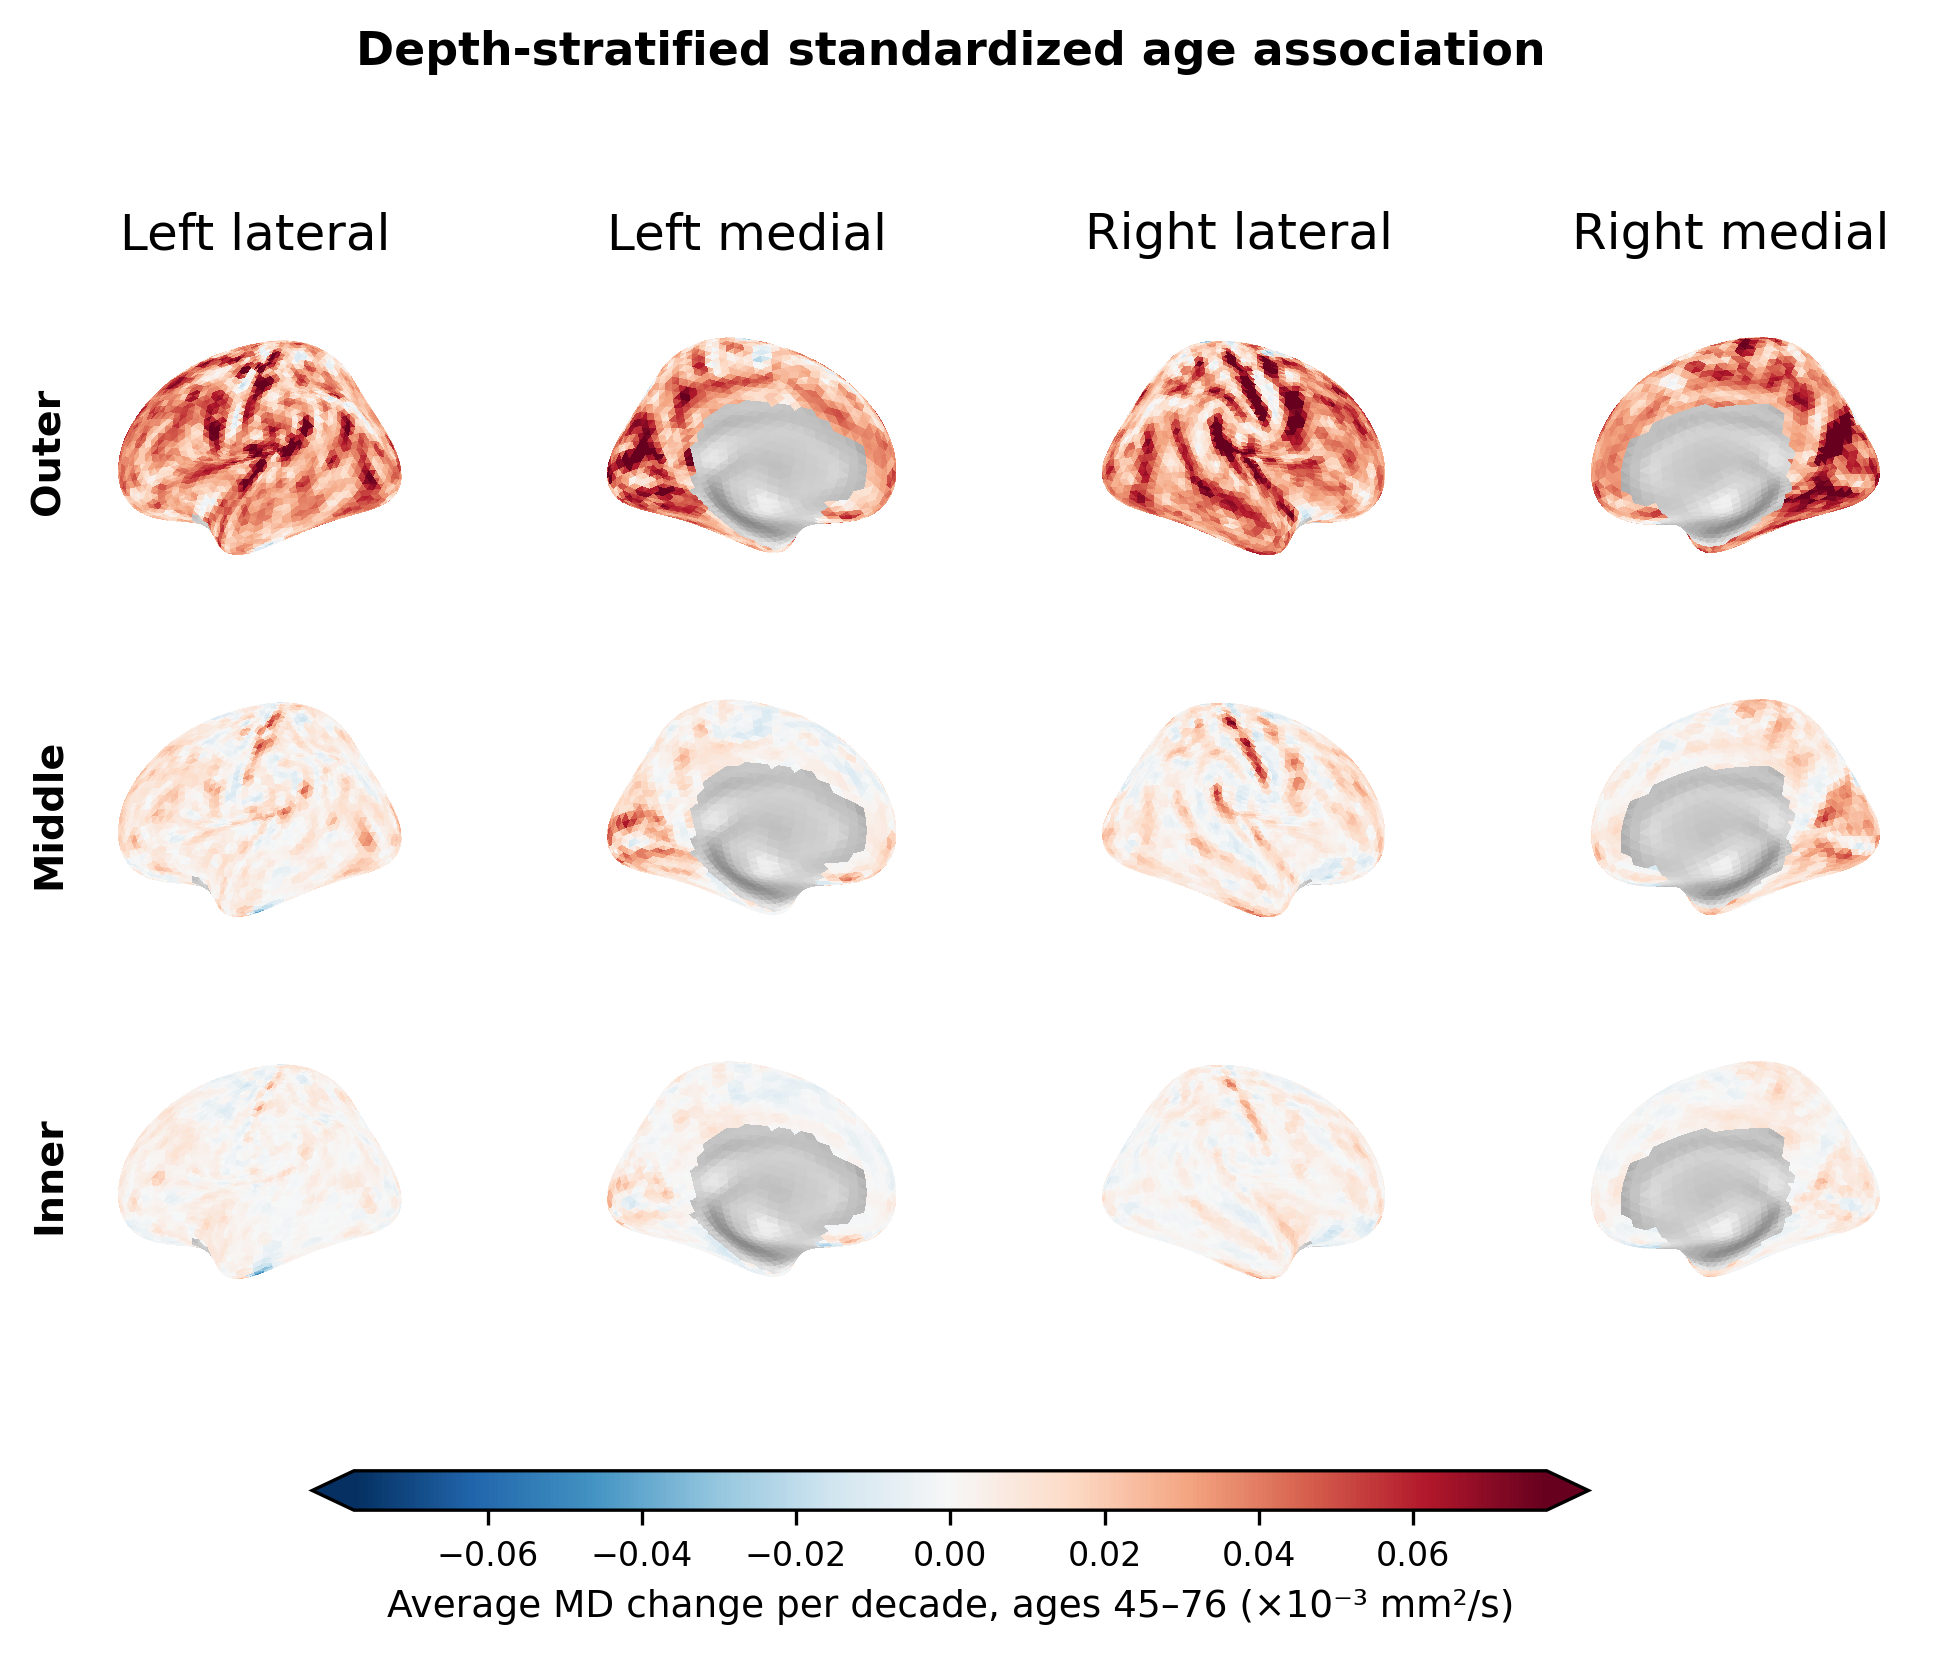

*Display note:* the common symmetric color limit is $L=P_{98}(|E|)=7.73132e-05$ mm²/s per decade. Endpoint colors and triangular colorbar extensions mark display saturation. The original data are not clipped: actual range [-8.70174e-05, 0.000174197] mm²/s per decade; 271/14,061 (2.00%) effects exceed ±L.

In [41]:
figure6c_qc = json.loads((FIG6C / "computation_qc.json").read_text())
rendering_qc = json.loads((FIG6C / "rendering_qc.json").read_text())
age_support = pd.read_csv(FIG6C / "age_support.csv")
covariate_support = pd.read_parquet(FIG6C / "node_covariate_support.parquet")
node_depth_effect = pd.read_parquet(FIG6C / "node_depth_standardized_age_effect.parquet")
band_effect = pd.read_parquet(FIG6C / "node_depth_band_standardized_age_effect.parquet")
surface_mapping = pd.read_csv(FIG6C / "surface_mapping_qc.csv")
curves = pd.read_parquet(FULL / "age_curve_shape_diagnostics.parquet")

assert figure6c_qc["status"] == rendering_qc["status"] == "complete"
assert len(node_depth_effect) == 4687 * 21
assert len(band_effect) == 4687 * 3
eligible = node_depth_effect["eligible_exact_186_subject_estimand"]
eligible_band = band_effect["eligible_exact_186_subject_estimand"]
effect_columns = ["standardized_mean_predicted_median_md_age45",
                  "standardized_mean_predicted_median_md_age76",
                  "average_md_change_per_decade_ages45_76"]
assert np.isfinite(node_depth_effect.loc[eligible, effect_columns]).all().all()
assert node_depth_effect.loc[~eligible, effect_columns].isna().all().all()

display(pd.DataFrame({
    "item": ["Frozen estimand", "Eligible nodes", "Unavailable nodes",
             "Finite node × depth effects", "MD unit", "Spatial interpolation"],
    "value": [figure6c_qc["estimand"], figure6c_qc["n_nodes_exact_186_estimand"],
              figure6c_qc["n_nodes_excluded_missing_local_thickness"],
              figure6c_qc["n_node_depth_models_predicted"], figure6c_qc["raw_md_unit"],
              rendering_qc["interpolation"]],
}))
display(age_support)
display(pd.DataFrame(figure6c_qc["thickness_support_against_nearby_ages"]).T)
display(surface_mapping)
display(pd.DataFrame([{
    "actual_min_mm2_s_per_decade": rendering_qc["raw_finite_min"],
    "actual_max_mm2_s_per_decade": rendering_qc["raw_finite_max"],
    "symmetric_display_limit_L": rendering_qc["symmetric_vmax_raw_mm2_per_s"],
    "clipped_negative_n": rendering_qc["n_below_negative_display_limit"],
    "clipped_positive_n": rendering_qc["n_above_positive_display_limit"],
    "clipped_total_n": rendering_qc["n_color_clipped"],
    "clipped_fraction": rendering_qc["fraction_color_clipped"],
}]))

band_summary = (band_effect.loc[band_effect["eligible_exact_186_subject_estimand"]]
                .groupby("depth_band", observed=True)
                ["depth_band_mean_average_md_change_per_decade"]
                .agg(["min", "median", "mean", "max"])) * 1e3
band_summary["positive_fraction"] = (band_effect.loc[
    band_effect["eligible_exact_186_subject_estimand"]]
    .groupby("depth_band", observed=True)
    ["depth_band_mean_average_md_change_per_decade"].apply(lambda x: (x > 0).mean()))
display(band_summary)
display(Markdown(
    "**relative_nonlinearity formula:** " +
    figure6c_qc["relative_nonlinearity"]["formula"] +
    "  \nThis saved curve-shape diagnostic is recorded but is not an inclusion premise."
))
display(Image(filename=str(FIG6C / "Figure6C_depth_stratified_age_association.png")))
display(Markdown(
    f"*Display note:* the common symmetric color limit is "
    f"$L=P_{{98}}(|E|)={rendering_qc['symmetric_vmax_raw_mm2_per_s']:.6g}$ mm²/s per decade. "
    f"Endpoint colors and triangular colorbar extensions mark display saturation. The original "
    f"data are not clipped: actual range "
    f"[{rendering_qc['raw_finite_min']:.6g}, {rendering_qc['raw_finite_max']:.6g}] mm²/s per "
    f"decade; {rendering_qc['n_color_clipped']:,}/{len(eligible_band):,} "
    f"({rendering_qc['fraction_color_clipped']:.2%}) effects exceed ±L."
))

# The 41–78-year endpoint sensitivity analysis remains saved in FIG6C_SUPP but is not
# displayed here, keeping the main notebook output focused on the primary 45–76 result.

### DK region × 21-depth descriptive age-association heatmap

This descriptive supplement aggregates the existing ico4 node × depth age effects without
refitting any model. For each hemisphere-specific DK region and depth, the heatmap uses the median
effect across eligible nodes in the fixed Figure 6C mask. The accompanying table also records the
25th and 75th percentiles, IQR, and valid-node coverage.

findfont: Failed to find font weight semibold, now using 700.


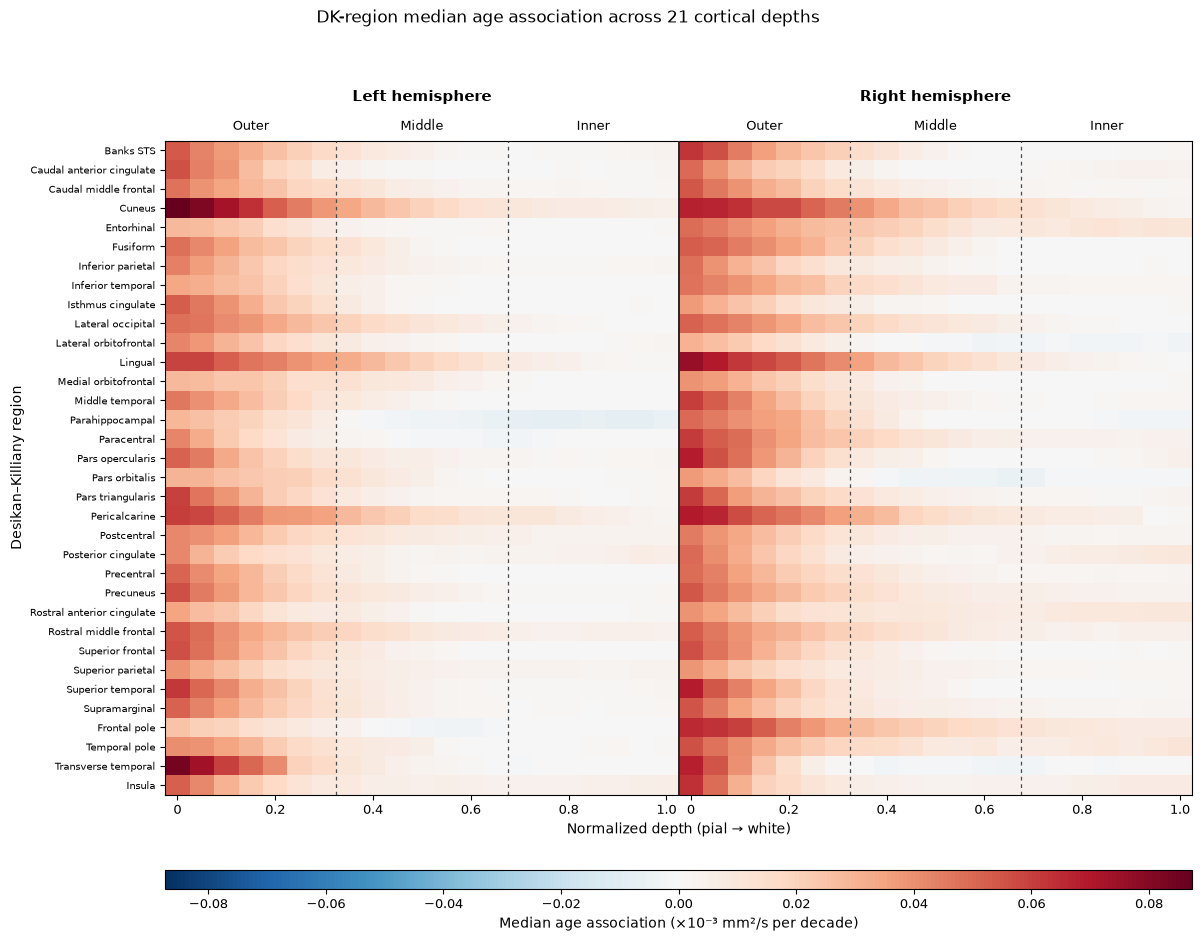

In [42]:
# Reuse the saved Figure 6C node × depth estimand; do not refit or interpolate.
HEATMAP_EFFECT_COLUMN = "average_md_change_per_decade_ages45_76"
assert figure6c_qc["raw_md_unit"] == "mm^2/s"
assert figure6c_qc["display_md_unit"] == "x10^-3 mm^2/s"

ico4_node_metadata = pd.read_csv(RESULT / "ico4_node_metadata.csv")
eligible_effect = node_depth_effect.loc[
    node_depth_effect["eligible_exact_186_subject_estimand"]
    & node_depth_effect[HEATMAP_EFFECT_COLUMN].notna()
].copy()
assert eligible_effect["node_index"].nunique() == 4_517
assert len(eligible_effect) == 4_517 * 21
assert not eligible_effect.duplicated(["node_index", "depth_index"]).any()

region_lookup = (ico4_node_metadata[["hemisphere", "dk_label_id", "dk_label_name"]]
                 .drop_duplicates()
                 .sort_values(["hemisphere", "dk_label_id"]))
depth_lookup = (node_depth_effect[["depth_index", "normalized_depth"]]
                .drop_duplicates()
                .sort_values("depth_index"))
assert region_lookup.groupby("hemisphere").size().to_dict() == {"lh": 34, "rh": 34}
assert depth_lookup["depth_index"].tolist() == list(range(21))

fixed_node_counts = (ico4_node_metadata
                     .groupby(["hemisphere", "dk_label_id", "dk_label_name"], as_index=False)
                     .agg(n_fixed_mask_nodes=("node_index", "nunique")))
dk_depth_stats = (eligible_effect
                  .groupby(["hemisphere", "dk_label_id", "dk_label_name",
                            "depth_index", "normalized_depth"], as_index=False,
                           observed=True)[HEATMAP_EFFECT_COLUMN]
                  .agg(
                      n_valid_nodes="count",
                      median_effect_mm2_s_per_decade="median",
                      q25_effect_mm2_s_per_decade=lambda values: values.quantile(0.25),
                      q75_effect_mm2_s_per_decade=lambda values: values.quantile(0.75),
                  ))

# Reindex to the complete 68-region × 21-depth grid so an empty cell remains explicit and gray.
dk_depth_grid = (region_lookup.assign(_join_key=1)
                 .merge(depth_lookup.assign(_join_key=1), on="_join_key")
                 .drop(columns="_join_key"))
dk_depth_summary = (dk_depth_grid
                    .merge(dk_depth_stats,
                           on=["hemisphere", "dk_label_id", "dk_label_name",
                               "depth_index", "normalized_depth"],
                           how="left", validate="one_to_one")
                    .merge(fixed_node_counts,
                           on=["hemisphere", "dk_label_id", "dk_label_name"],
                           how="left", validate="many_to_one"))
dk_depth_summary["n_valid_nodes"] = (
    dk_depth_summary["n_valid_nodes"].fillna(0).astype(int))
dk_depth_summary["valid_node_fraction"] = (
    dk_depth_summary["n_valid_nodes"] / dk_depth_summary["n_fixed_mask_nodes"])
dk_depth_summary["iqr_effect_mm2_s_per_decade"] = (
    dk_depth_summary["q75_effect_mm2_s_per_decade"]
    - dk_depth_summary["q25_effect_mm2_s_per_decade"])
dk_depth_summary["depth_band"] = pd.cut(
    dk_depth_summary["depth_index"], bins=[-0.5, 6.5, 13.5, 20.5],
    labels=["Outer", "Middle", "Inner"], right=False, ordered=True,
)

# Raw effects are mm²/s per decade. Multiply exactly once for the Figure 6C display unit.
for statistic in ("median", "q25", "q75", "iqr"):
    raw_column = f"{statistic}_effect_mm2_s_per_decade"
    display_column = f"{statistic}_effect_x1e3_mm2_s_per_decade"
    dk_depth_summary[display_column] = 1e3 * dk_depth_summary[raw_column]

hemisphere_order = pd.CategoricalDtype(["lh", "rh"], ordered=True)
dk_depth_summary["hemisphere"] = dk_depth_summary["hemisphere"].astype(hemisphere_order)
dk_depth_summary = dk_depth_summary.sort_values(
    ["hemisphere", "dk_label_id", "depth_index"]).reset_index(drop=True)
assert len(dk_depth_summary) == 2 * 34 * 21
assert dk_depth_summary["n_valid_nodes"].sum() == 4_517 * 21

summary_columns = [
    "hemisphere", "dk_label_id", "dk_label_name", "depth_index", "normalized_depth",
    "depth_band", "n_valid_nodes", "n_fixed_mask_nodes", "valid_node_fraction",
    "median_effect_mm2_s_per_decade", "q25_effect_mm2_s_per_decade",
    "q75_effect_mm2_s_per_decade", "iqr_effect_mm2_s_per_decade",
    "median_effect_x1e3_mm2_s_per_decade", "q25_effect_x1e3_mm2_s_per_decade",
    "q75_effect_x1e3_mm2_s_per_decade", "iqr_effect_x1e3_mm2_s_per_decade",
]
dk_depth_summary = dk_depth_summary[summary_columns]
summary_csv = FIG6C / "dk_region_depth_age_effect_summary.csv"
summary_parquet = FIG6C / "dk_region_depth_age_effect_summary.parquet"
dk_depth_summary.to_csv(summary_csv, index=False)
dk_depth_summary.to_parquet(summary_parquet, index=False)

DK_DISPLAY_NAMES = {
    "bankssts": "Banks STS", "caudalanteriorcingulate": "Caudal anterior cingulate",
    "caudalmiddlefrontal": "Caudal middle frontal", "cuneus": "Cuneus",
    "entorhinal": "Entorhinal", "fusiform": "Fusiform",
    "inferiorparietal": "Inferior parietal", "inferiortemporal": "Inferior temporal",
    "isthmuscingulate": "Isthmus cingulate", "lateraloccipital": "Lateral occipital",
    "lateralorbitofrontal": "Lateral orbitofrontal", "lingual": "Lingual",
    "medialorbitofrontal": "Medial orbitofrontal", "middletemporal": "Middle temporal",
    "parahippocampal": "Parahippocampal", "paracentral": "Paracentral",
    "parsopercularis": "Pars opercularis", "parsorbitalis": "Pars orbitalis",
    "parstriangularis": "Pars triangularis", "pericalcarine": "Pericalcarine",
    "postcentral": "Postcentral", "posteriorcingulate": "Posterior cingulate",
    "precentral": "Precentral", "precuneus": "Precuneus",
    "rostralanteriorcingulate": "Rostral anterior cingulate",
    "rostralmiddlefrontal": "Rostral middle frontal",
    "superiorfrontal": "Superior frontal", "superiorparietal": "Superior parietal",
    "superiortemporal": "Superior temporal", "supramarginal": "Supramarginal",
    "frontalpole": "Frontal pole", "temporalpole": "Temporal pole",
    "transversetemporal": "Transverse temporal", "insula": "Insula",
}
dk_order = (region_lookup.query("hemisphere == 'lh'")
            .sort_values("dk_label_id")["dk_label_name"].tolist())
assert set(dk_order) == set(DK_DISPLAY_NAMES)

plot_column = "median_effect_x1e3_mm2_s_per_decade"
heatmap_matrices = {}
for hemisphere in ("lh", "rh"):
    heatmap_matrices[hemisphere] = (dk_depth_summary
        .query("hemisphere == @hemisphere")
        .pivot(index="dk_label_name", columns="depth_index", values=plot_column)
        .reindex(index=dk_order, columns=range(21)))

pooled_values = np.concatenate([
    matrix.to_numpy(float).ravel() for matrix in heatmap_matrices.values()
])
heatmap_limit = float(np.nanmax(np.abs(pooled_values)))
assert np.isfinite(heatmap_limit) and heatmap_limit > 0
heatmap_cmap = plt.get_cmap("RdBu_r").copy()
heatmap_cmap.set_bad("#D0D0D0")
heatmap_norm = TwoSlopeNorm(vmin=-heatmap_limit, vcenter=0, vmax=heatmap_limit)

combined_heatmap = np.concatenate(
    [heatmap_matrices[hemisphere].to_numpy(float) for hemisphere in ("lh", "rh")],
    axis=1,
)
assert combined_heatmap.shape == (34, 42)

# Render both hemispheres as contiguous 21-column blocks in one heatmap.
fig, ax = plt.subplots(figsize=(13.0, 10.5))
image_handle = ax.imshow(
    np.ma.masked_invalid(combined_heatmap),
    aspect="auto", origin="upper", interpolation="none",
    cmap=heatmap_cmap, norm=heatmap_norm,
)
depth_tick_positions = [0, 4, 8, 12, 16, 20]
ax.set_xticks(
    depth_tick_positions + [position + 21 for position in depth_tick_positions],
    ["0", "0.2", "0.4", "0.6", "0.8", "1.0"] * 2,
)
ax.set_xlabel("Normalized depth (pial → white)")
ax.set_yticks(range(34), [DK_DISPLAY_NAMES[name] for name in dk_order])
ax.set_ylabel("Desikan–Killiany region")
ax.tick_params(axis="y", labelsize=7)

for boundary in (6.5, 13.5, 27.5, 34.5):
    ax.axvline(boundary, color="#4A4A4A", linewidth=0.9,
               linestyle=(0, (3, 3)), zorder=3)
ax.axvline(20.5, color="#262626", linewidth=1.4, zorder=4)

for center, label in (
    (3, "Outer"), (10, "Middle"), (17, "Inner"),
    (24, "Outer"), (31, "Middle"), (38, "Inner"),
):
    ax.text(center, 1.012, label, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
for center, label in ((10, "Left hemisphere"), (31, "Right hemisphere")):
    ax.text(center, 1.055, label, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=11, fontweight="semibold")

fig.suptitle("DK-region median age association across 21 cortical depths", y=0.985)
colorbar = fig.colorbar(
    image_handle, ax=ax, orientation="horizontal", fraction=0.035, pad=0.10, aspect=55)
colorbar.set_label("Median age association (×10⁻³ mm²/s per decade)")
fig.subplots_adjust(left=0.19, right=0.98, bottom=0.14, top=0.86)

heatmap_stem = FIG6C / "Figure6C_DK_region_by_depth_age_association_heatmap"
fig.savefig(heatmap_stem.with_suffix(".png"), dpi=600, bbox_inches="tight")
fig.savefig(heatmap_stem.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

# Additional bilateral-combined result: pool eligible left- and right-hemisphere nodes within
# each matching DK region and depth, then calculate the node-level median and IQR.
bilateral_region_lookup = (region_lookup[["dk_label_id", "dk_label_name"]]
                           .drop_duplicates()
                           .sort_values("dk_label_id"))
assert len(bilateral_region_lookup) == 34
bilateral_fixed_node_counts = (ico4_node_metadata
    .groupby(["dk_label_id", "dk_label_name"], as_index=False)
    .agg(n_fixed_mask_nodes=("node_index", "nunique")))
bilateral_depth_stats = (eligible_effect
    .groupby(["dk_label_id", "dk_label_name", "depth_index", "normalized_depth"],
             as_index=False, observed=True)[HEATMAP_EFFECT_COLUMN]
    .agg(
        n_valid_nodes="count",
        median_effect_mm2_s_per_decade="median",
        q25_effect_mm2_s_per_decade=lambda values: values.quantile(0.25),
        q75_effect_mm2_s_per_decade=lambda values: values.quantile(0.75),
    ))
bilateral_depth_grid = (bilateral_region_lookup.assign(_join_key=1)
    .merge(depth_lookup.assign(_join_key=1), on="_join_key")
    .drop(columns="_join_key"))
bilateral_depth_summary = (bilateral_depth_grid
    .merge(
        bilateral_depth_stats,
        on=["dk_label_id", "dk_label_name", "depth_index", "normalized_depth"],
        how="left", validate="one_to_one",
    )
    .merge(
        bilateral_fixed_node_counts,
        on=["dk_label_id", "dk_label_name"],
        how="left", validate="many_to_one",
    ))
bilateral_depth_summary["n_valid_nodes"] = (
    bilateral_depth_summary["n_valid_nodes"].fillna(0).astype(int))
bilateral_depth_summary["valid_node_fraction"] = (
    bilateral_depth_summary["n_valid_nodes"]
    / bilateral_depth_summary["n_fixed_mask_nodes"])
bilateral_depth_summary["iqr_effect_mm2_s_per_decade"] = (
    bilateral_depth_summary["q75_effect_mm2_s_per_decade"]
    - bilateral_depth_summary["q25_effect_mm2_s_per_decade"])
bilateral_depth_summary["depth_band"] = pd.cut(
    bilateral_depth_summary["depth_index"], bins=[-0.5, 6.5, 13.5, 20.5],
    labels=["Outer", "Middle", "Inner"], right=False, ordered=True,
)
for statistic in ("median", "q25", "q75", "iqr"):
    raw_column = f"{statistic}_effect_mm2_s_per_decade"
    display_column = f"{statistic}_effect_x1e3_mm2_s_per_decade"
    bilateral_depth_summary[display_column] = 1e3 * bilateral_depth_summary[raw_column]

bilateral_depth_summary.insert(0, "aggregation_scope", "bilateral_combined")
bilateral_depth_summary = bilateral_depth_summary.sort_values(
    ["dk_label_id", "depth_index"]).reset_index(drop=True)
assert len(bilateral_depth_summary) == 34 * 21
assert bilateral_depth_summary["n_valid_nodes"].sum() == 4_517 * 21

bilateral_summary_csv = FIG6C / "dk_region_depth_age_effect_bilateral_combined_summary.csv"
bilateral_summary_parquet = FIG6C / "dk_region_depth_age_effect_bilateral_combined_summary.parquet"
bilateral_depth_summary.to_csv(bilateral_summary_csv, index=False)
bilateral_depth_summary.to_parquet(bilateral_summary_parquet, index=False)

bilateral_heatmap_matrix = (bilateral_depth_summary
    .pivot(index="dk_label_name", columns="depth_index", values=plot_column)
    .reindex(index=dk_order, columns=range(21)))
assert bilateral_heatmap_matrix.shape == (34, 21)

fig, ax = plt.subplots(figsize=(8.0, 10.5))
bilateral_image_handle = ax.imshow(
    np.ma.masked_invalid(bilateral_heatmap_matrix.to_numpy(float)),
    aspect="auto", origin="upper", interpolation="none",
    cmap=heatmap_cmap, norm=heatmap_norm,
)
ax.set_xticks(depth_tick_positions, ["0", "0.2", "0.4", "0.6", "0.8", "1.0"])
ax.set_xlabel("Normalized depth (pial → white)")
ax.set_yticks(range(34), [DK_DISPLAY_NAMES[name] for name in dk_order])
ax.set_ylabel("Desikan–Killiany region")
ax.tick_params(axis="y", labelsize=7)
for boundary in (6.5, 13.5):
    ax.axvline(boundary, color="#4A4A4A", linewidth=0.9,
               linestyle=(0, (3, 3)), zorder=3)
for center, label in ((3, "Outer"), (10, "Middle"), (17, "Inner")):
    ax.text(center, 1.012, label, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
fig.suptitle(
    "Bilateral-combined DK-region median age association across 21 cortical depths",
    y=0.985,
)
bilateral_colorbar = fig.colorbar(
    bilateral_image_handle, ax=ax, orientation="horizontal",
    fraction=0.035, pad=0.10, aspect=45,
)
bilateral_colorbar.set_label("Median age association (×10⁻³ mm²/s per decade)")
fig.subplots_adjust(left=0.27, right=0.98, bottom=0.14, top=0.91)

bilateral_heatmap_stem = (
    FIG6C / "Figure6C_DK_region_by_depth_age_association_bilateral_combined_heatmap")
fig.savefig(bilateral_heatmap_stem.with_suffix(".png"), dpi=600, bbox_inches="tight")
fig.savefig(bilateral_heatmap_stem.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

# Check label alignment and left-right regional node support.
left_labels = (region_lookup.query("hemisphere == 'lh'")
    [["dk_label_id", "dk_label_name"]]
    .rename(columns={"dk_label_name": "left_dk_label_name"}))
right_labels = (region_lookup.query("hemisphere == 'rh'")
    [["dk_label_id", "dk_label_name"]]
    .rename(columns={"dk_label_name": "right_dk_label_name"}))
left_right_label_mapping = left_labels.merge(
    right_labels, on="dk_label_id", how="outer", indicator=True, validate="one_to_one")
left_right_label_mapping["label_id_present_both"] = (
    left_right_label_mapping["_merge"] == "both")
left_right_label_mapping["label_name_match"] = (
    left_right_label_mapping["left_dk_label_name"]
    == left_right_label_mapping["right_dk_label_name"])
assert len(left_right_label_mapping) == 34
assert left_right_label_mapping["label_id_present_both"].all()
assert left_right_label_mapping["label_name_match"].all()
left_right_label_mapping = left_right_label_mapping.drop(columns="_merge")

valid_region_node_counts = (eligible_effect
    [["hemisphere", "dk_label_id", "dk_label_name", "node_index"]]
    .drop_duplicates()
    .groupby(["hemisphere", "dk_label_id", "dk_label_name"], as_index=False)
    .agg(n_valid_nodes=("node_index", "nunique")))
region_support = fixed_node_counts.merge(
    valid_region_node_counts,
    on=["hemisphere", "dk_label_id", "dk_label_name"],
    how="left", validate="one_to_one")
region_support["n_valid_nodes"] = region_support["n_valid_nodes"].fillna(0).astype(int)
region_support["valid_node_fraction"] = (
    region_support["n_valid_nodes"] / region_support["n_fixed_mask_nodes"])

def support_for_hemisphere(hemisphere, prefix):
    selected = region_support.query("hemisphere == @hemisphere")[
        ["dk_label_id", "dk_label_name", "n_valid_nodes",
         "n_fixed_mask_nodes", "valid_node_fraction"]].copy()
    return selected.rename(columns={
        "dk_label_name": f"{prefix}_dk_label_name",
        "n_valid_nodes": f"{prefix}_n_valid_nodes",
        "n_fixed_mask_nodes": f"{prefix}_n_fixed_mask_nodes",
        "valid_node_fraction": f"{prefix}_valid_node_fraction",
    })

left_right_comparability = (left_right_label_mapping
    .merge(support_for_hemisphere("lh", "left"),
           on=["dk_label_id", "left_dk_label_name"], validate="one_to_one")
    .merge(support_for_hemisphere("rh", "right"),
           on=["dk_label_id", "right_dk_label_name"], validate="one_to_one"))
left_right_comparability["valid_node_difference_right_minus_left"] = (
    left_right_comparability["right_n_valid_nodes"]
    - left_right_comparability["left_n_valid_nodes"])
left_right_comparability["absolute_valid_node_difference"] = (
    left_right_comparability["valid_node_difference_right_minus_left"].abs())
left_right_comparability["coverage_difference_right_minus_left"] = (
    left_right_comparability["right_valid_node_fraction"]
    - left_right_comparability["left_valid_node_fraction"])
left_right_comparability["absolute_coverage_difference"] = (
    left_right_comparability["coverage_difference_right_minus_left"].abs())
left_right_comparability["valid_node_ratio_smaller_to_larger"] = (
    left_right_comparability[["left_n_valid_nodes", "right_n_valid_nodes"]].min(axis=1)
    / left_right_comparability[["left_n_valid_nodes", "right_n_valid_nodes"]].max(axis=1))
left_right_comparability = left_right_comparability.sort_values("dk_label_id").reset_index(drop=True)
left_right_comparability.to_csv(
    FIG6C / "dk_region_left_right_comparability.csv", index=False)
left_right_comparability.to_parquet(
    FIG6C / "dk_region_left_right_comparability.parquet", index=False)
display(left_right_comparability.sort_values(
    ["absolute_coverage_difference", "absolute_valid_node_difference"],
    ascending=False).head(10))

# Exact leave-one-node-out median bounds: largest possible influence of any single node.
def leave_one_out_median_bounds(values):
    ordered = np.sort(np.asarray(values, dtype=float))
    n_values = len(ordered)
    full_median = float(np.median(ordered))
    if n_values <= 1:
        return full_median, np.nan, np.nan, np.nan
    midpoint = n_values // 2
    if n_values % 2 == 0:
        loo_min, loo_max = float(ordered[midpoint - 1]), float(ordered[midpoint])
    else:
        candidates = np.array([
            (ordered[midpoint] + ordered[midpoint + 1]) / 2,
            (ordered[midpoint - 1] + ordered[midpoint + 1]) / 2,
            (ordered[midpoint - 1] + ordered[midpoint]) / 2,
        ])
        loo_min, loo_max = float(candidates.min()), float(candidates.max())
    max_abs_change = max(abs(loo_min - full_median), abs(loo_max - full_median))
    return full_median, loo_min, loo_max, max_abs_change

loo_group_columns = ["hemisphere", "dk_label_id", "dk_label_name",
                     "depth_index", "normalized_depth"]
loo_records = []
for group_key, group in eligible_effect.groupby(loo_group_columns, observed=True):
    full_median, loo_min, loo_max, max_abs_change = leave_one_out_median_bounds(
        group[HEATMAP_EFFECT_COLUMN].to_numpy(float))
    loo_records.append({
        **dict(zip(loo_group_columns, group_key)),
        "loo_full_median_effect_mm2_s_per_decade": full_median,
        "loo_median_min_mm2_s_per_decade": loo_min,
        "loo_median_max_mm2_s_per_decade": loo_max,
        "max_abs_single_node_median_change_mm2_s_per_decade": max_abs_change,
    })
loo_sensitivity = pd.DataFrame(loo_records)
assert len(loo_sensitivity) == 2 * 34 * 21

difference_keys = ["dk_label_id", "dk_label_name", "depth_index",
                   "normalized_depth", "depth_band"]
difference_values = ["median_effect_mm2_s_per_decade", "q25_effect_mm2_s_per_decade",
    "q75_effect_mm2_s_per_decade", "iqr_effect_mm2_s_per_decade",
    "n_valid_nodes", "n_fixed_mask_nodes", "valid_node_fraction"]

def depth_summary_for_hemisphere(hemisphere, prefix):
    selected = dk_depth_summary.query("hemisphere == @hemisphere")[
        difference_keys + difference_values].copy()
    return selected.rename(columns={column: f"{prefix}_{column}"
                                    for column in difference_values})

left_right_difference = depth_summary_for_hemisphere("lh", "left").merge(
    depth_summary_for_hemisphere("rh", "right"),
    on=difference_keys, how="outer", validate="one_to_one")
assert len(left_right_difference) == 34 * 21

def loo_for_hemisphere(hemisphere, prefix):
    columns = ["loo_median_min_mm2_s_per_decade",
               "loo_median_max_mm2_s_per_decade",
               "max_abs_single_node_median_change_mm2_s_per_decade"]
    keys = ["dk_label_id", "dk_label_name", "depth_index", "normalized_depth"]
    selected = loo_sensitivity.query("hemisphere == @hemisphere")[keys + columns].copy()
    return selected.rename(columns={column: f"{prefix}_{column}" for column in columns})

loo_keys = ["dk_label_id", "dk_label_name", "depth_index", "normalized_depth"]
left_right_difference = (left_right_difference
    .merge(loo_for_hemisphere("lh", "left"), on=loo_keys, validate="one_to_one")
    .merge(loo_for_hemisphere("rh", "right"), on=loo_keys, validate="one_to_one"))
left_right_difference["difference_right_minus_left_mm2_s_per_decade"] = (
    left_right_difference["right_median_effect_mm2_s_per_decade"]
    - left_right_difference["left_median_effect_mm2_s_per_decade"])
difference_candidates = pd.concat([
    left_right_difference["right_loo_median_min_mm2_s_per_decade"]
        - left_right_difference["left_median_effect_mm2_s_per_decade"],
    left_right_difference["right_loo_median_max_mm2_s_per_decade"]
        - left_right_difference["left_median_effect_mm2_s_per_decade"],
    left_right_difference["right_median_effect_mm2_s_per_decade"]
        - left_right_difference["left_loo_median_min_mm2_s_per_decade"],
    left_right_difference["right_median_effect_mm2_s_per_decade"]
        - left_right_difference["left_loo_median_max_mm2_s_per_decade"],
], axis=1)
left_right_difference["single_node_loo_difference_min_mm2_s_per_decade"] = (
    difference_candidates.min(axis=1, skipna=True))
left_right_difference["single_node_loo_difference_max_mm2_s_per_decade"] = (
    difference_candidates.max(axis=1, skipna=True))
full_difference = left_right_difference["difference_right_minus_left_mm2_s_per_decade"]
left_right_difference["max_abs_single_node_difference_change_mm2_s_per_decade"] = np.maximum(
    (left_right_difference["single_node_loo_difference_min_mm2_s_per_decade"] - full_difference).abs(),
    (left_right_difference["single_node_loo_difference_max_mm2_s_per_decade"] - full_difference).abs())
left_right_difference["single_node_influence_to_abs_difference_ratio"] = np.where(
    full_difference.abs() > 0,
    left_right_difference["max_abs_single_node_difference_change_mm2_s_per_decade"]
        / full_difference.abs(), np.nan)
left_right_difference["difference_sign_stable_under_any_single_node_removal"] = (
    (left_right_difference["single_node_loo_difference_min_mm2_s_per_decade"] > 0)
    | (left_right_difference["single_node_loo_difference_max_mm2_s_per_decade"] < 0))
left_right_difference["valid_node_difference_right_minus_left"] = (
    left_right_difference["right_n_valid_nodes"] - left_right_difference["left_n_valid_nodes"])
left_right_difference["coverage_difference_right_minus_left"] = (
    left_right_difference["right_valid_node_fraction"]
    - left_right_difference["left_valid_node_fraction"])
for raw_column in ["left_median_effect_mm2_s_per_decade",
                   "right_median_effect_mm2_s_per_decade",
                   "difference_right_minus_left_mm2_s_per_decade",
                   "single_node_loo_difference_min_mm2_s_per_decade",
                   "single_node_loo_difference_max_mm2_s_per_decade",
                   "max_abs_single_node_difference_change_mm2_s_per_decade"]:
    display_column = raw_column.replace("mm2_s_per_decade", "x1e3_mm2_s_per_decade")
    left_right_difference[display_column] = 1e3 * left_right_difference[raw_column]
left_right_difference = left_right_difference.sort_values(
    ["dk_label_id", "depth_index"]).reset_index(drop=True)
left_right_difference.to_csv(
    FIG6C / "dk_region_depth_age_effect_right_minus_left_summary.csv", index=False)
left_right_difference.to_parquet(
    FIG6C / "dk_region_depth_age_effect_right_minus_left_summary.parquet", index=False)
display(left_right_difference.sort_values(
    "single_node_influence_to_abs_difference_ratio", ascending=False,
    na_position="last").head(10))

difference_plot_column = "difference_right_minus_left_x1e3_mm2_s_per_decade"
difference_heatmap_matrix = (left_right_difference
    .pivot(index="dk_label_name", columns="depth_index", values=difference_plot_column)
    .reindex(index=dk_order, columns=range(21)))
assert difference_heatmap_matrix.shape == (34, 21)
difference_limit = float(np.nanmax(np.abs(difference_heatmap_matrix.to_numpy(float))))
assert np.isfinite(difference_limit) and difference_limit > 0
difference_norm = TwoSlopeNorm(vmin=-difference_limit, vcenter=0, vmax=difference_limit)
fig, ax = plt.subplots(figsize=(8.0, 10.5))
difference_image_handle = ax.imshow(
    np.ma.masked_invalid(difference_heatmap_matrix.to_numpy(float)),
    aspect="auto", origin="upper", interpolation="none",
    cmap=heatmap_cmap, norm=difference_norm)
ax.set_xticks(depth_tick_positions, ["0", "0.2", "0.4", "0.6", "0.8", "1.0"])
ax.set_xlabel("Normalized depth (pial → white)")
ax.set_yticks(range(34), [DK_DISPLAY_NAMES[name] for name in dk_order])
ax.set_ylabel("Desikan–Killiany region")
ax.tick_params(axis="y", labelsize=7)
for boundary in (6.5, 13.5):
    ax.axvline(boundary, color="#4A4A4A", linewidth=0.9,
               linestyle=(0, (3, 3)), zorder=3)
for center, label in ((3, "Outer"), (10, "Middle"), (17, "Inner")):
    ax.text(center, 1.012, label, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
fig.suptitle("DK-region age-association difference: right minus left", y=0.985)
difference_colorbar = fig.colorbar(
    difference_image_handle, ax=ax, orientation="horizontal",
    fraction=0.035, pad=0.10, aspect=45)
difference_colorbar.set_label(
    "Right − left median age association (×10⁻³ mm²/s per decade)")
fig.subplots_adjust(left=0.27, right=0.98, bottom=0.14, top=0.91)
difference_heatmap_stem = (
    FIG6C / "Figure6C_DK_region_by_depth_age_association_right_minus_left_heatmap")
fig.savefig(difference_heatmap_stem.with_suffix(".png"), dpi=600, bbox_inches="tight")
fig.savefig(difference_heatmap_stem.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

The heatmap reports the median of the existing ico4 node-level age effects within each
hemisphere-specific DK region; it is not a refitted regional normative model. The IQR in the
exported table describes spatial heterogeneity among nodes within a region and is not a confidence
interval. The left- and right-hemisphere 21-depth blocks are displayed contiguously in one heatmap
and separated by a solid vertical line; their hemisphere-specific estimates are not pooled. Cells
without eligible nodes are gray. No depth interpolation, smoothing, or significance marking is
applied. This figure is descriptive, and color differences do not establish statistically significant
differences between depths.

The additional bilateral-combined heatmap pools eligible nodes from the matching left and right DK
regions before calculating the median at each depth. It is therefore a node-level bilateral summary,
not the average of the two hemisphere-specific medians and not a refitted regional model. Its IQR
likewise describes spatial heterogeneity among pooled nodes rather than uncertainty in the median.

The right-minus-left heatmap subtracts the left hemisphere-specific regional median from the
matching right regional median at each depth. Label-ID/name alignment and left-right node support
are checked explicitly. The exported sensitivity fields give the exact range of the difference after
removing any one eligible node from either hemisphere; they are descriptive influence diagnostics,
not confidence intervals or significance tests. No statistical significance is inferred from the
difference colors or from sign stability under single-node deletion.

The map uses the original-MD-scale age-76 minus age-45 difference in the equal-weight mean of 186
subject-conditional predicted medians, multiplied by 10/31. The same participants, weights,
numeric sex codes, and node-local thickness values are used at both ages. Nodes lacking complete
186-person thickness are not imputed or reweighted and render gray. Outer, middle, and inner bands
are equal-weight averages of depths 0--6, 7--13, and 14--20. The map is descriptive: color
differences between bands are not evidence of statistically significant depth specificity.
For display only, the common symmetric limit is the pooled 98th percentile of absolute valid band
effects; triangular colorbar extensions indicate saturated values. Original numeric and surface
data remain untruncated.

The 41–78-year supplement repeats the calculation over the complete observed age range. Because
only three participants fall within ±3 years of age 41, it is retained as an endpoint sensitivity
analysis and does not replace the 45–76-year primary map.

The integrated overview combines the DK-region model-selection evidence with final ico4 held-out
calibration and one reproducibly selected original-scale conditional reference curve. Regional
and ico4 predictive log likelihood values are not compared across spatial scales.

## 9. CN participant age-distribution tables

In [43]:
# Retain the exact plotting inputs and numerical summaries used by the cohort figures.
def make_age_distribution_table(frame):
    counts = frame.groupby("age").size().rename("n_subjects").reset_index()
    counts["percent"] = 100 * counts["n_subjects"] / len(frame)
    return counts

def make_decade_selection_table(frame):
    labels = ["20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "≥80"]
    groups = pd.cut(frame["age"], bins=[20, 30, 40, 50, 60, 70, 80, np.inf],
                    labels=labels, right=False, ordered=True)
    table = groups.value_counts(sort=False).reindex(labels, fill_value=0).rename("n_subjects").reset_index()
    table.columns = ["age_group", "n_subjects"]
    table["percent"] = 100 * table["n_subjects"] / len(frame)
    table["retained_in_40_to_79"] = table["age_group"].isin(
        ["40–49", "50–59", "60–69", "70–79"])
    return table

image_qc_age_table = make_age_distribution_table(image_qc_cn)
final_age_table = make_age_distribution_table(final_cn)
decade_selection_table = make_decade_selection_table(image_qc_cn)
image_qc_summary = age_summary(image_qc_cn, "CN subjects after source-image QC")
final_age_summary = age_summary(final_cn, "CN subjects aged 40–79 years")

if WRITE_FIGURES:
    image_qc_age_table.to_csv(
        NOTEBOOK_FIGURE_DIR / "age_distribution_cn_after_image_qc.csv", index=False)
    final_age_table.to_csv(
        NOTEBOOK_FIGURE_DIR / "age_distribution_final_cn_186.csv", index=False)
    decade_selection_table.to_csv(
        NOTEBOOK_FIGURE_DIR / "age_distribution_decade_selection_after_image_qc.csv", index=False)
    image_qc_summary.to_csv(
        NOTEBOOK_FIGURE_DIR / "age_summary_cn_after_image_qc.csv", index=False)
    final_age_summary.to_csv(
        NOTEBOOK_FIGURE_DIR / "age_summary_final_cn_186.csv", index=False)

display(image_qc_summary)
display(final_age_summary)
display(decade_selection_table)
display(final_age_table)

,cohort,n_subjects,minimum_age,maximum_age,mean_age,sd_age,median_age,q1_age,q3_age
0,CN subjects after source-image QC,194,28.0,78.0,58.061856,10.549478,56.0,51.0,67.0


,cohort,n_subjects,minimum_age,maximum_age,mean_age,sd_age,median_age,q1_age,q3_age
0,CN subjects aged 40–79 years,186,41.0,78.0,59.112903,9.420687,58.0,52.0,67.0


,age_group,n_subjects,percent,retained_in_40_to_79
0,20–29,1,0.515464,False
1,30–39,7,3.608247,False
2,40–49,30,15.463918,True
3,50–59,78,40.206186,True
4,60–69,43,22.164948,True
5,70–79,35,18.041237,True
6,≥80,0,0.000000,False


,age,n_subjects,percent
0,41.0,2,1.075269
1,44.0,1,0.537634
2,45.0,6,3.225806
3,46.0,4,2.150538
4,47.0,1,0.537634
5,48.0,8,4.301075
6,49.0,8,4.301075
7,50.0,4,2.150538
8,51.0,9,4.838710
9,52.0,10,5.376344


## 10. Exported artifacts

In [44]:
artifacts = pd.DataFrame({
    "artifact": [
        "OOF prediction index", "Invalid availability mask", "Overall calibration",
        "Stratified calibration", "Participant-bootstrap CIs", "Node × depth calibration",
        "Full-model parameter index", "Full centile index", "Age-curve diagnostics",
        "Representative-node centiles", "Representative-node locator",
        "Representative-node curves, sex code 2",
        "Representative-node curves, sex code 1 supplement",
        "Cohort age groups after source-image QC", "Final CN age distribution",
        "Regional Gaussian/Warped z distributions", "ico4 diagnostic summary",
        "ico4 held-out z distribution", "ico4 Q-Q plot", "ico4 overall coverage",
        "Depth-wise mean z", "Depth-wise SD(z)", "Depth-wise coverage deviation",
        "Depth-wise extreme-z fraction",
        "Figure 6C DK-region × depth heatmap PNG",
        "Figure 6C DK-region × depth heatmap PDF",
        "Figure 6C DK-region × depth summary CSV",
        "Figure 6C DK-region × depth summary Parquet",
        "Figure 6C bilateral-combined DK-region × depth heatmap PNG",
        "Figure 6C bilateral-combined DK-region × depth heatmap PDF",
        "Figure 6C bilateral-combined DK-region × depth summary CSV",
        "Figure 6C bilateral-combined DK-region × depth summary Parquet",
        "Figure 6C left-right comparability CSV",
        "Figure 6C left-right comparability Parquet",
        "Figure 6C right-minus-left heatmap PNG",
        "Figure 6C right-minus-left heatmap PDF",
        "Figure 6C right-minus-left summary CSV",
        "Figure 6C right-minus-left summary Parquet",
        "Figure 6C node-depth effects",
        "Figure 6C depth-band effects", "Figure 6C support QC", "Figure 6C map",
        "Figure 6C 41-78 supplement effects", "Figure 6C 41-78 supplement map",
        "Integrated Figure 6 overview",
        "Integrated numerical summary",
    ],
    "path": [
        OOF / "prediction_file_index.parquet", OOF / "invalid_availability_positions.parquet",
        OOF / "calibration_overall.csv", OOF / "calibration_by_depth_hemisphere_age_group.csv",
        OOF / "subject_bootstrap_calibration_ci.csv", OOF / "calibration_by_node_depth.parquet",
        FULL / "parameter_file_index.parquet", FULL / "centile_file_index.parquet",
        FULL / "age_curve_shape_diagnostics.parquet", FULL / "representative_node_centiles.parquet",
        ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_node_locations.png",
        ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_nodes_sex_code_2.png",
        ROOT / "notebook_figures" / "ico4_final_model_results_186" / "figure6a_representative_nodes_sex_code_1_supplement.png",
        NOTEBOOK_FIGURE_DIR / "age_groups_cn_after_image_qc_with_boundaries.png",
        NOTEBOOK_FIGURE_DIR / "age_distribution_final_cn_186.png",
        NOTEBOOK_FIGURE_DIR / "regional_gaussian_vs_warped_oof_z_distribution.png",
        NOTEBOOK_FIGURE_DIR / "ico4_diagnostic_summary.png",
        NOTEBOOK_FIGURE_DIR / "ico4_heldout_z_distribution.png",
        NOTEBOOK_FIGURE_DIR / "oof_qq_001_999.png",
        NOTEBOOK_FIGURE_DIR / "oof_observed_vs_nominal_coverage.png",
        NOTEBOOK_FIGURE_DIR / "oof_depth_mean_z.png",
        NOTEBOOK_FIGURE_DIR / "oof_depth_sd_z.png",
        NOTEBOOK_FIGURE_DIR / "oof_depth_coverage_deviation.png",
        NOTEBOOK_FIGURE_DIR / "oof_depth_fraction_abs_z_gt_3.png",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_heatmap.png",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_heatmap.pdf",
        FIG6C / "dk_region_depth_age_effect_summary.csv",
        FIG6C / "dk_region_depth_age_effect_summary.parquet",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_bilateral_combined_heatmap.png",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_bilateral_combined_heatmap.pdf",
        FIG6C / "dk_region_depth_age_effect_bilateral_combined_summary.csv",
        FIG6C / "dk_region_depth_age_effect_bilateral_combined_summary.parquet",
        FIG6C / "dk_region_left_right_comparability.csv",
        FIG6C / "dk_region_left_right_comparability.parquet",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_right_minus_left_heatmap.png",
        FIG6C / "Figure6C_DK_region_by_depth_age_association_right_minus_left_heatmap.pdf",
        FIG6C / "dk_region_depth_age_effect_right_minus_left_summary.csv",
        FIG6C / "dk_region_depth_age_effect_right_minus_left_summary.parquet",
        FIG6C / "node_depth_standardized_age_effect.parquet",
        FIG6C / "node_depth_band_standardized_age_effect.parquet",
        FIG6C / "computation_qc.json", FIG6C / "Figure6C_depth_stratified_age_association.png",
        FIG6C_SUPP / "node_depth_standardized_age_effect.parquet",
        FIG6C_SUPP / "Figure6C_supplement_age41_78.png",
        SUMMARY / "figure6_overall_summary.png",
        SUMMARY / "figure6_numerical_summary.csv",
    ],
})
artifacts["exists"] = artifacts.path.map(Path.is_file)
display(artifacts)
assert artifacts.exists.all()

,artifact,path,exists
0,OOF prediction index,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
1,Invalid availability mask,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
2,Overall calibration,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
3,Stratified calibration,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
4,Participant-bootstrap CIs,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
5,Node × depth calibration,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
6,Full-model parameter index,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
7,Full centile index,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
8,Age-curve diagnostics,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
9,Representative-node centiles,/mnt/newStor/paros/paros_WORK/xintong/code/cor...,True
